# Plotting of figures in R (Ulcerative Colitis)

**INPUT:**
- interactions.RData file (generated in the calculate_communication.ipynb notebook)

**OUTPUT:**
- interactions_f_s.csv
- interactions_f_r.csv
- interactions_a_s.csv
- interactions_a_r.csv
- interactions_e_s_l.csv
- interactions_e_r_r.csv
- interactions_rho_s.csv
- interactions_rho_r.csv

**FIGURES:** 
- 2b (Main)
- 2c (Main)
- 2d (Main)
- 4a (Suppl.)
- 4b (Suppl.)
- 4d (Suppl.)
- 5a (Suppl.)
- 5b (Suppl.)

# Import

In [1]:
library(community)
library(tidyr)
library(ggplot2)
library(dplyr)
library(gridExtra)

Warning message:
“Paket ‘community’ wurde unter R Version 4.2.2 erstellt”

Attache Paket: ‘dplyr’


Die folgenden Objekte sind maskiert von ‘package:stats’:

    filter, lag


Die folgenden Objekte sind maskiert von ‘package:base’:

    intersect, setdiff, setequal, union



Attache Paket: ‘gridExtra’


Das folgende Objekt ist maskiert ‘package:dplyr’:

    combine




In [2]:
suppressWarnings(load("./pdata/interactions.RData"))

In [3]:
data("visualization_functions")

# Preprocessing

In [4]:
immune_cell_types <- c("Tregs", "Mast", "Macrophages", "Plasma", "CD8", "CD4", "B-cells", "Myeloid")

In [5]:
# indices
idx_sign <- !is.na(interactions$anno_interactions$sign) & interactions$anno_interactions$sign
idx_up   <- interactions$anno_interactions$log2FC_weights > 1
idx_down <- interactions$anno_interactions$log2FC_weights < -1

In [6]:
# IDs of significantly up- or downregulated interactions (used by all forest plots)
IDs <- as.character(unique(c(
    interactions$anno_interactions$interaction_ID[idx_up & idx_sign],
    interactions$anno_interactions$interaction_ID[idx_down & idx_sign]
)))

In [7]:
# common component limits for the forest plots
ordered_IDs <- order_IDs_by_interaction_categories(interactions)
component_lim <- find_component_limits(interactions, ordered_IDs)

# Figure 2b

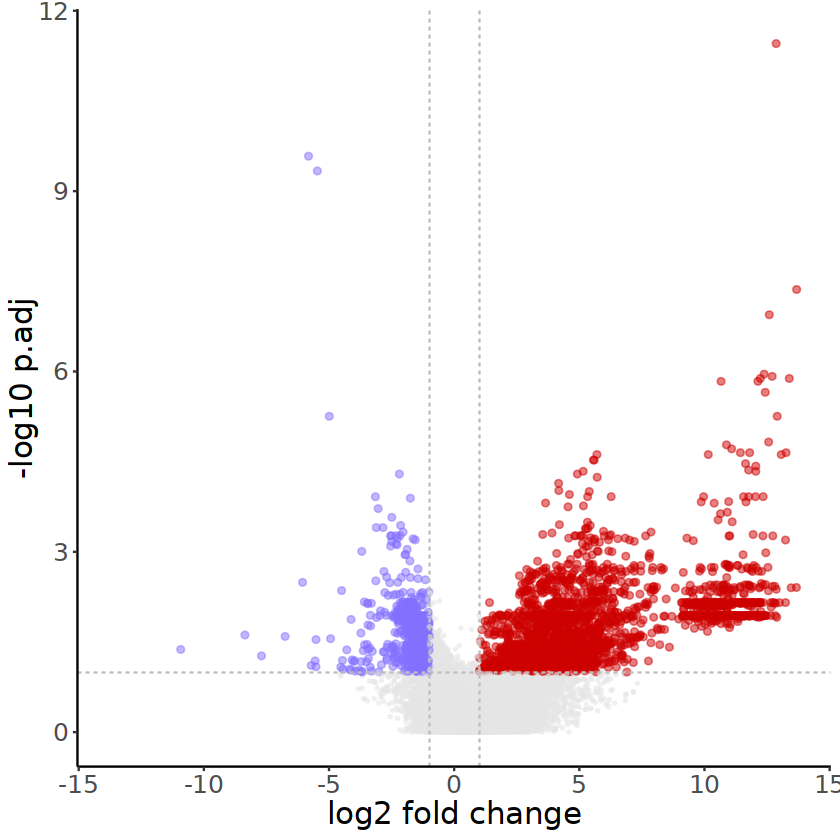

In [8]:
volcano_plot <- plot_vulcano(interactions)

volcano_plot + theme(panel.border = element_blank(),
                     axis.line = element_line(color = "black"),
                     panel.grid.major = element_blank(),
                     panel.grid.minor = element_blank(),
                     panel.background = element_rect(fill = "white", colour = "white"))

# Figure 2c

In [9]:
# Count, per cell type, the significant up-/downregulated interactions it participates in
# (each interaction credits its sending AND its receiving cell type)
interactions_data <- cbind(interactions$anno_interactions, idx_up, idx_down, idx_sign)

sending_counts_up <- interactions_data %>%
  filter(idx_up & idx_sign) %>%
  group_by(sending_cell_type) %>%
  summarize(count = n(), .groups = "drop") %>%
  mutate(cell_type = sending_cell_type, regulation = "Upregulated") %>%
  select(-sending_cell_type)

receiving_counts_up <- interactions_data %>%
  filter(idx_up & idx_sign) %>%
  group_by(receiving_cell_type) %>%
  summarize(count = n(), .groups = "drop") %>%
  mutate(cell_type = receiving_cell_type, regulation = "Upregulated") %>%
  select(-receiving_cell_type)

sending_counts_down <- interactions_data %>%
  filter(idx_down & idx_sign) %>%
  group_by(sending_cell_type) %>%
  summarize(count = n(), .groups = "drop") %>%
  mutate(cell_type = sending_cell_type, regulation = "Downregulated") %>%
  select(-sending_cell_type)

receiving_counts_down <- interactions_data %>%
  filter(idx_down & idx_sign) %>%
  group_by(receiving_cell_type) %>%
  summarize(count = n(), .groups = "drop") %>%
  mutate(cell_type = receiving_cell_type, regulation = "Downregulated") %>%
  select(-receiving_cell_type)

combined_counts <- bind_rows(sending_counts_up, receiving_counts_up,
                             sending_counts_down, receiving_counts_down) %>%
  group_by(cell_type, regulation) %>%
  summarize(total_count = sum(count), .groups = "drop")

# Zero-fill both directions so no cell type is dropped
combined_counts_filled <- combined_counts %>%
  tidyr::complete(cell_type, regulation, fill = list(total_count = 0))

# Order cell types by number of upregulated interactions (ascending after coord_flip)
ordered_cell_types_filled <- combined_counts_filled %>%
  filter(regulation == "Upregulated") %>%
  arrange(-total_count) %>%
  pull(cell_type) %>%
  rev()

combined_counts_filled$cell_type <- factor(combined_counts_filled$cell_type,
                                           levels = ordered_cell_types_filled)
levels(combined_counts_filled$cell_type)[levels(combined_counts_filled$cell_type) == "Stem and multipotent cells"] <- "Stem and\nmultipotent cells"

# True number of significant differential interactions (not participations)
total_all_interactions <- sum(idx_sign & (idx_up | idx_down), na.rm = TRUE)

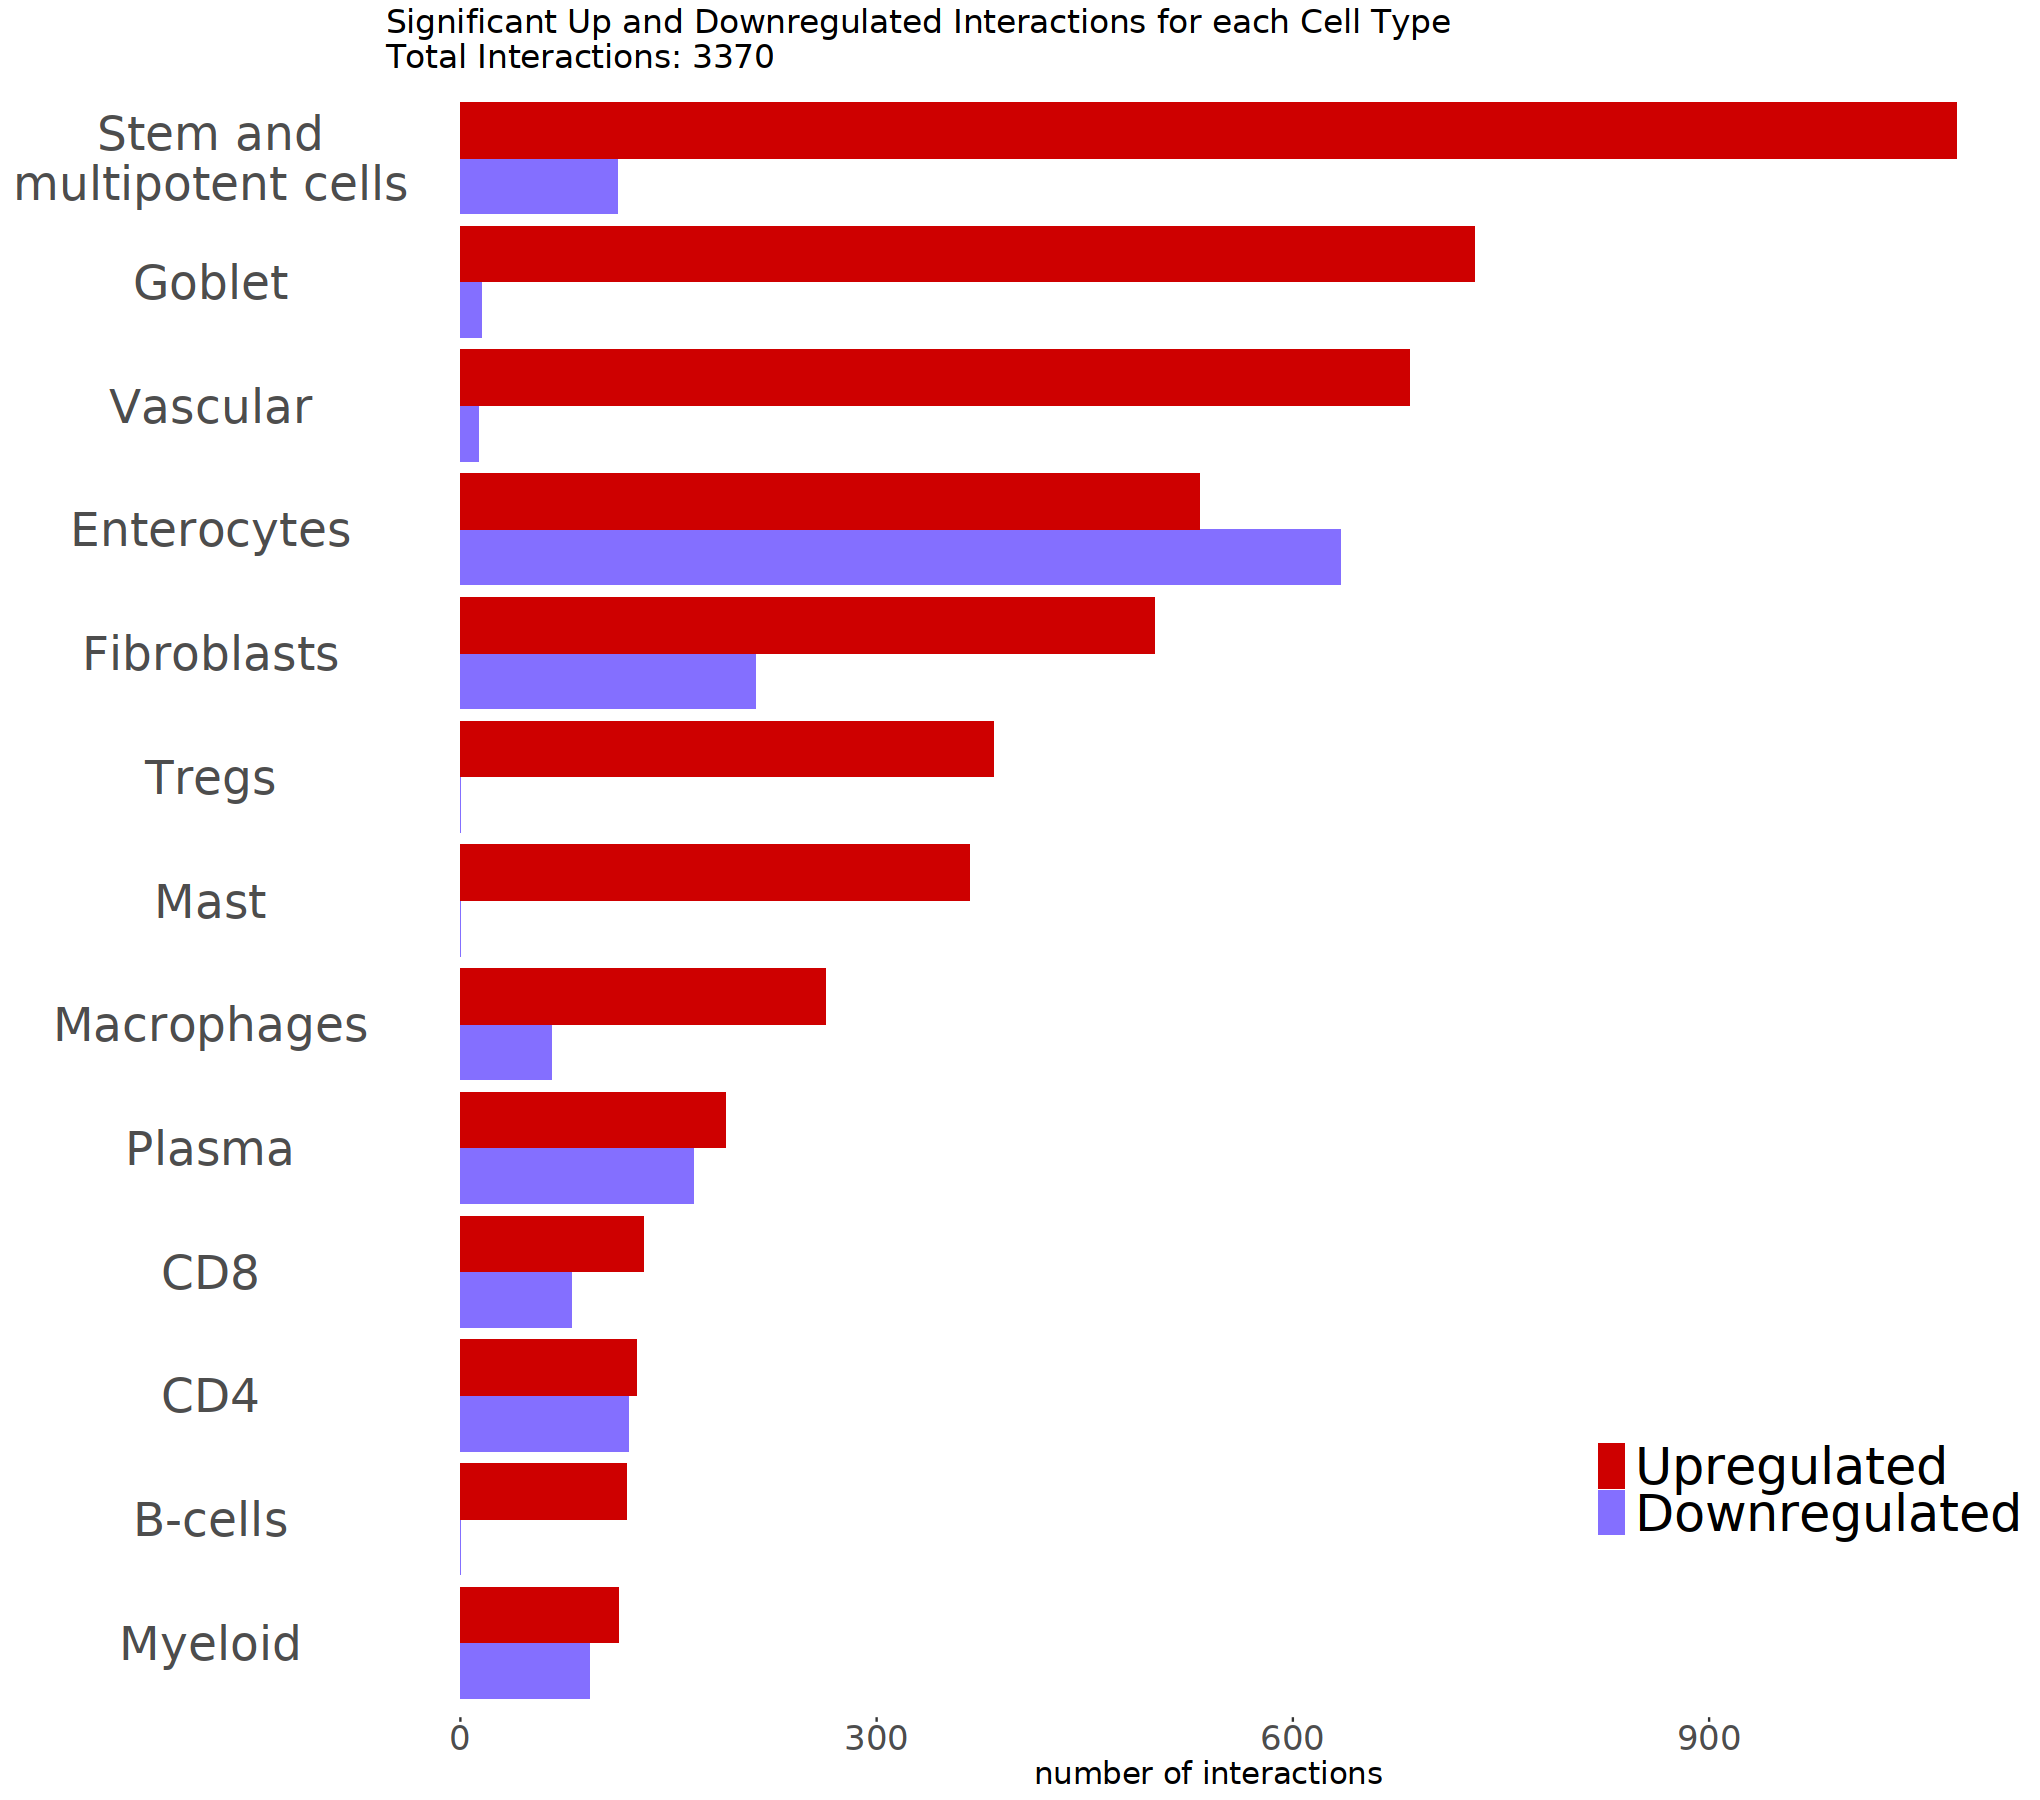

In [10]:
options(repr.plot.width=17, repr.plot.height=15)

ggplot(combined_counts_filled, aes(x = cell_type, y = total_count, fill = regulation)) +
  geom_bar(stat = "identity", position = position_dodge(width = 0.9), width = 0.9) +
  coord_flip() +
  scale_fill_manual(values = c("Upregulated" = "#CE0000", "Downregulated" = "#846FFF"),
                  breaks = c("Upregulated", "Downregulated")) +
  theme(
  text = element_text(size=16, family="Helvetica"),
  axis.text.y = element_text(angle = 0, hjust = 0.5, size = 28),
  axis.ticks.y = element_blank(),
  axis.text = element_text(size = 20),
  axis.title = element_text(size=18),
  legend.position = "inside",
  legend.position.inside = c(0.85, 0.15),
  legend.title = element_text(size=16),
  legend.text = element_text(size=30),
  panel.background = element_blank(),
  panel.grid.major = element_blank(),
  panel.grid.minor = element_blank()
) +
  labs(y = "number of interactions", x = "", fill = "",
       title = paste("Significant Up and Downregulated Interactions for each Cell Type\nTotal Interactions:", total_all_interactions))

# Figure 2d

In [11]:
# Genes are SELECTED by cell-type-normalized frequency (top 25); bars and ordering show absolute interaction counts.
anno_interactions_df <- as.data.frame(interactions$anno_interactions)

filtered_interactions <- anno_interactions_df %>%
  filter(!is.na(p.value) & sign == TRUE) %>%
  arrange(p.value)

# Count frequencies of all genes
all_genes <- c(filtered_interactions$ligand_gene_name, filtered_interactions$receptor_gene_name)
sorted_total_count <- sort(table(all_genes), decreasing = TRUE)

# Count unique cell types per gene
ligand_cell <- select(filtered_interactions, ligand_gene_name, sending_cell_type)
receptor_cell <- select(filtered_interactions, receptor_gene_name, receiving_cell_type)
names(ligand_cell) <- c("gene", "cell_type")
names(receptor_cell) <- c("gene", "cell_type")

unique_cell_count <- rbind(ligand_cell, receptor_cell) %>%
  group_by(gene) %>%
  summarise(n_unique_cells = n_distinct(cell_type))

# Normalize frequency by number of cell types the gene appears in
sorted_total_count_df <- as.data.frame(as.table(sorted_total_count))
names(sorted_total_count_df) <- c("all_genes", "Freq")
merged_df <- left_join(sorted_total_count_df, unique_cell_count, by = c("all_genes" = "gene"))
merged_df$Normalized_Freq <- merged_df$Freq / merged_df$n_unique_cells

# Select top 25 genes by normalized frequency, display first 20 ordered by raw frequency
top_25_genes_sorted <- merged_df %>%
  arrange(desc(Normalized_Freq)) %>%
  head(25) %>%
  arrange(desc(Freq)) %>%
  head(20)

# Mark each interaction as immune or non-immune
filtered_interactions <- filtered_interactions %>%
  mutate(
    interaction_type = if_else(
      sending_cell_type %in% immune_cell_types | receiving_cell_type %in% immune_cell_types,
      "Immune",
      "Non-immune"
    )
  )

gene_summary <- filtered_interactions %>%
  select(ligand_gene_name, receptor_gene_name, interaction_type) %>%
  pivot_longer(cols = c(ligand_gene_name, receptor_gene_name), names_to = "role", values_to = "gene") %>%
  group_by(gene) %>%
  summarise(
    Immune = sum(interaction_type == "Immune"),
    Non_immune = sum(interaction_type == "Non-immune"),
    .groups = 'drop'
  )

final_summary <- top_25_genes_sorted %>%
  left_join(gene_summary, by = c("all_genes" = "gene")) %>%
  mutate(Check = Freq == (Immune + Non_immune))

stopifnot(all(final_summary$Check))

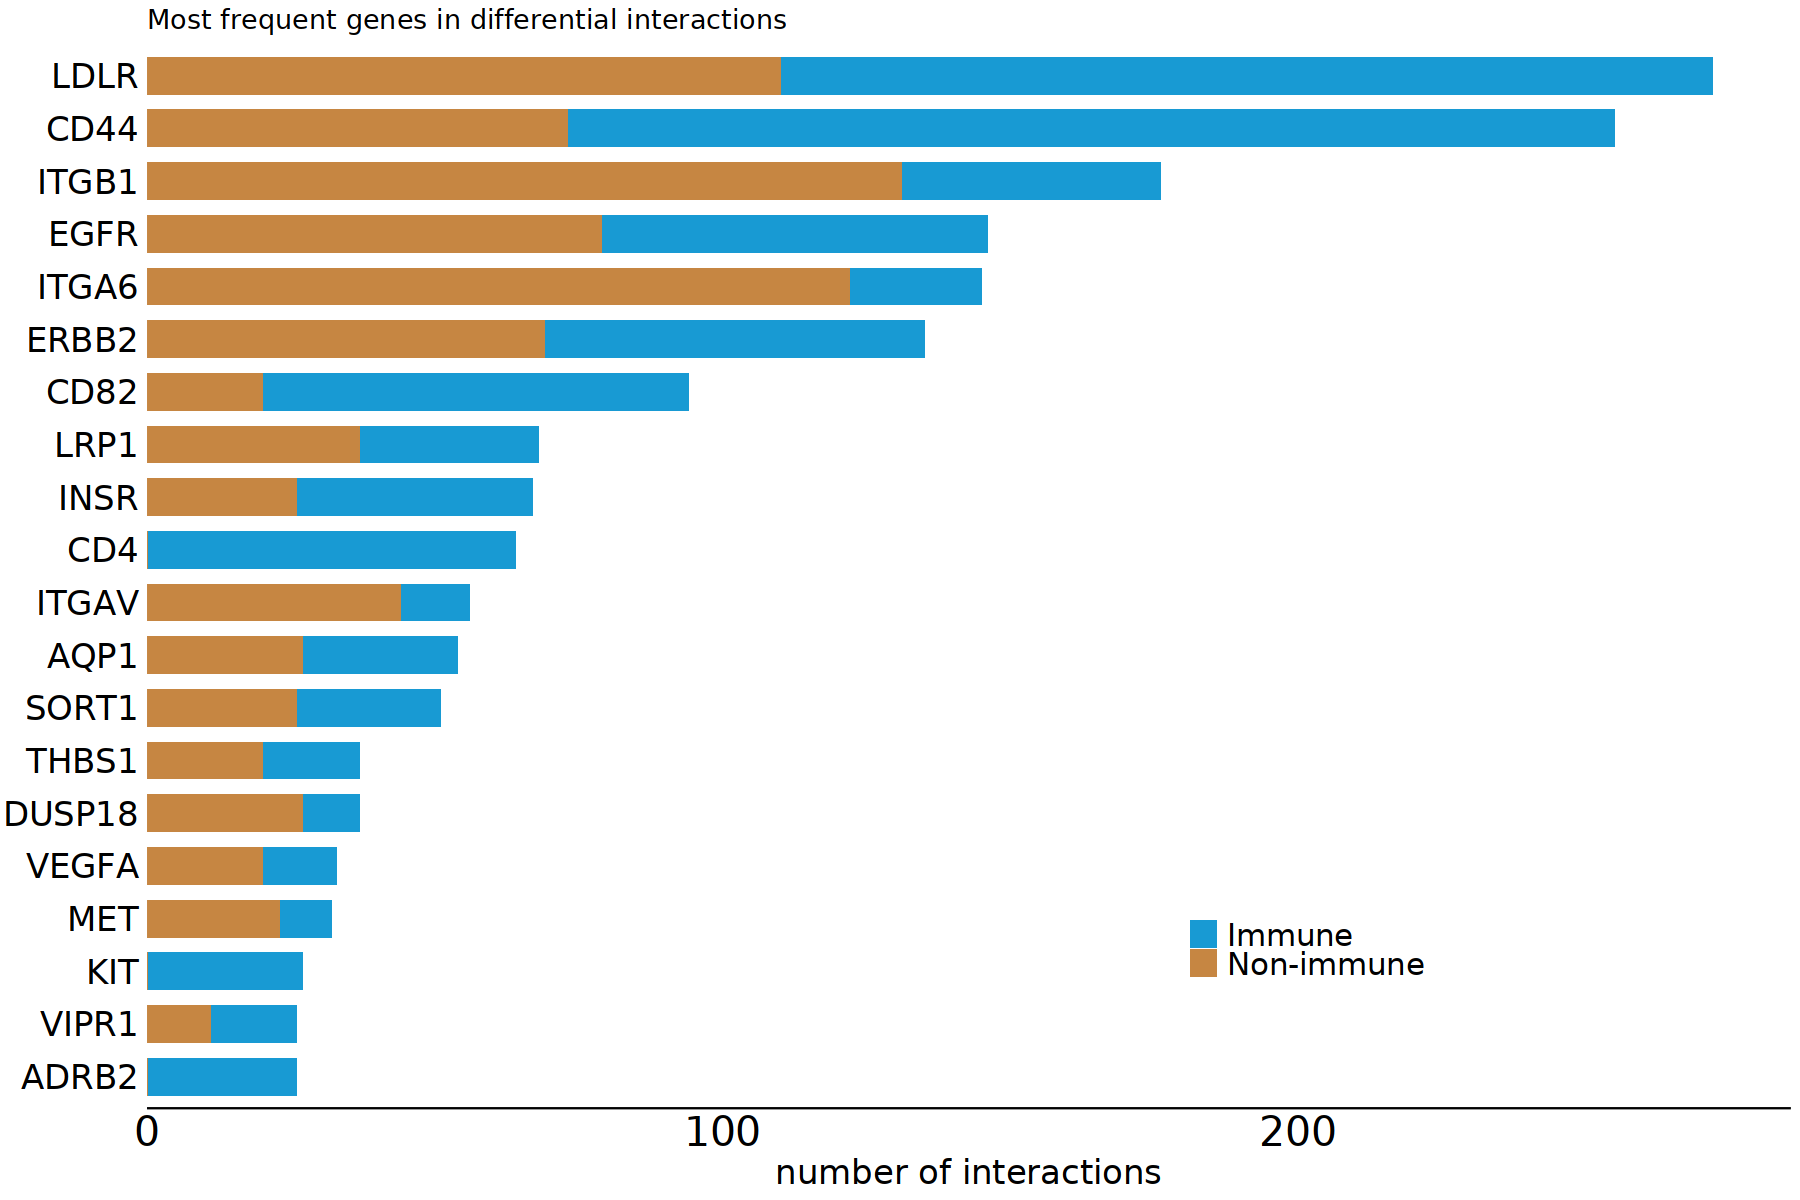

In [12]:
options(repr.plot.height = 10, repr.plot.width = 15)

final_summary_long <- final_summary %>%
  tidyr::pivot_longer(cols = c(Immune, Non_immune), names_to = "interaction_type", values_to = "count")

ggplot(final_summary_long, aes(x = reorder(all_genes, Freq), y = count, fill = interaction_type)) +
  geom_bar(stat = "identity", position = "stack", width = 0.7) +
  scale_fill_manual(values = c("Immune" = "#189ad3", "Non_immune" = "#c68642"),
                    labels = c("Immune" = "Immune", "Non_immune" = "Non-immune")) +
  coord_flip() +
  labs(x = "", y = "number of interactions",
       title = "Most frequent genes in differential interactions") +
  theme_minimal() +
  theme(
  axis.text.y = element_text(size = 20, face = "italic", color = "black"),
  axis.text.x = element_text(size = 24, color = "black"),
  axis.ticks.y = element_blank(),
  axis.title.y = element_blank(),
  axis.title.x = element_text(size = 20),
  panel.grid = element_blank(),
  axis.line.x = element_line(color = "black"),
  plot.title = element_text(size = 16, face = "bold"),
  legend.position = "inside",
  legend.position.inside = c(0.7, 0.15),
  legend.text = element_text(size = 18),
  legend.title = element_blank()
) +
  scale_y_continuous(expand = expansion(mult = c(0, 0.05)))

# Suppl. Figure 4a

In [13]:
ordered_cell_types <- c('Myeloid', 'B-cells', 'CD4', 'CD8', 'Plasma', 'Macrophages', 'Mast', 'Tregs',
                        'Fibroblasts', 'Enterocytes', 'Vascular', 'Goblet', 'Stem and multipotent cells')

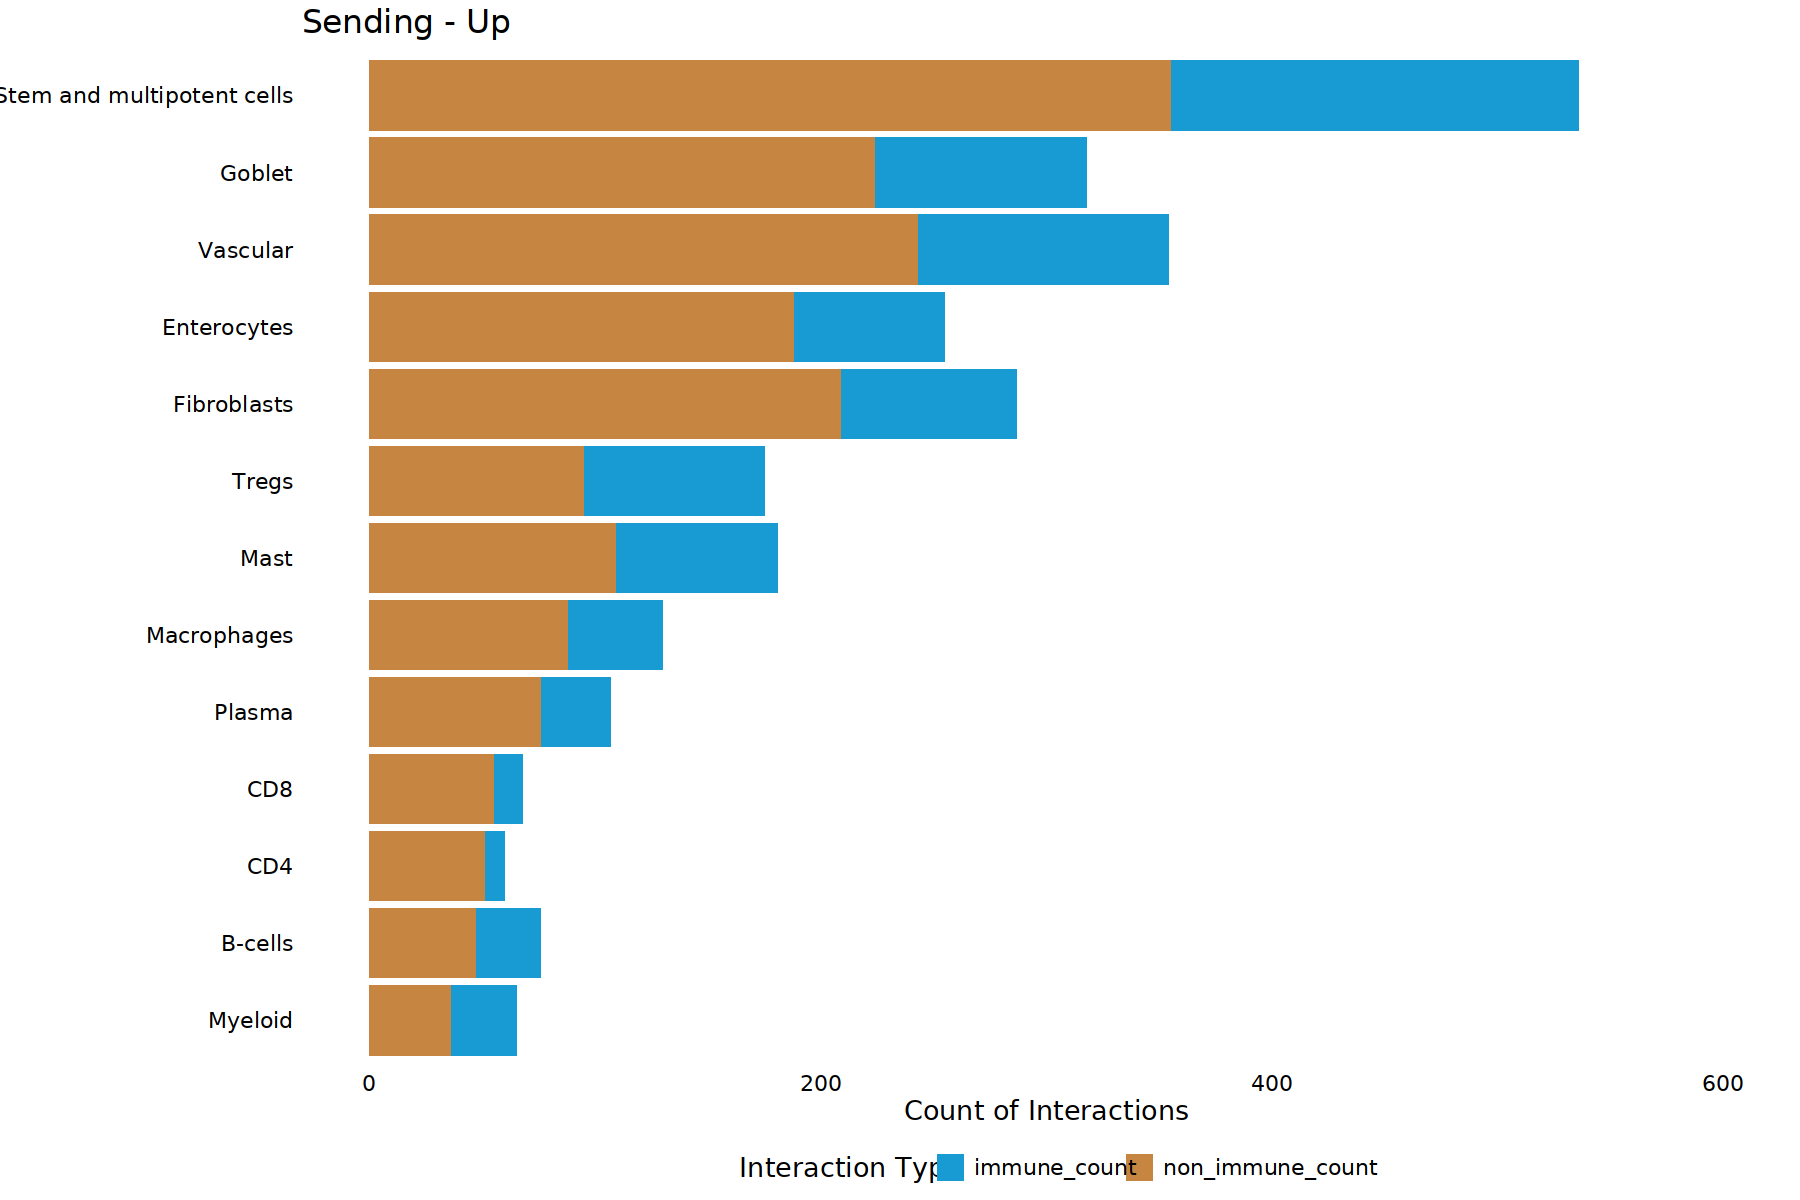

In [14]:
# Sending - Up
sending_up_total <- interactions$anno_interactions %>%
  filter(idx_up & idx_sign) %>%
  group_by(sending_cell_type) %>%
  summarise(total_count = n(), .groups = 'drop')

sending_up_immune <- interactions$anno_interactions %>%
  filter(idx_up & idx_sign & receiving_cell_type %in% immune_cell_types) %>%
  group_by(sending_cell_type) %>%
  summarise(immune_count = n(), .groups = 'drop')

sending_up_data <- merge(sending_up_total, sending_up_immune, by = "sending_cell_type", all.x = TRUE)
sending_up_data$immune_count[is.na(sending_up_data$immune_count)] <- 0
sending_up_data$non_immune_count <- sending_up_data$total_count - sending_up_data$immune_count

# Ensure all cell types are included, even those with zero interactions
sending_up_data_complete <- merge(data.frame(sending_cell_type = ordered_cell_types), sending_up_data, by = "sending_cell_type", all = TRUE)
sending_up_data_complete$immune_count[is.na(sending_up_data_complete$immune_count)] <- 0
sending_up_data_complete$non_immune_count[is.na(sending_up_data_complete$non_immune_count)] <- 0

sending_up_data_long <- tidyr::pivot_longer(sending_up_data_complete,
                                      cols = c("immune_count", "non_immune_count"),
                                      names_to = "interaction_type",
                                      values_to = "count")
sending_up_data_long$sending_cell_type <- factor(sending_up_data_long$sending_cell_type, levels = ordered_cell_types)

ggplot(sending_up_data_long, aes(x = sending_cell_type, y = count, fill = interaction_type)) +
  geom_bar(stat = "identity", position = "stack") +
  scale_fill_manual(values = c("non_immune_count" = '#c68642', "immune_count" = "#189ad3")) +
  coord_flip(ylim = c(0, 600)) +
  xlab("") +
  ylab("Count of Interactions") +
  ggtitle("Sending - Up") +
  theme_minimal() +
  theme(
    text = element_text(family = "Helvetica", size = 16),
    axis.text.x = element_text(size = 13, color = "black"),
    axis.text.y = element_text(size = 13, color = "black"),
    panel.grid.major = element_blank(),
    panel.grid.minor = element_blank(),
    legend.position = "bottom"
  ) +
  guides(fill = guide_legend(title = "Interaction Type"))

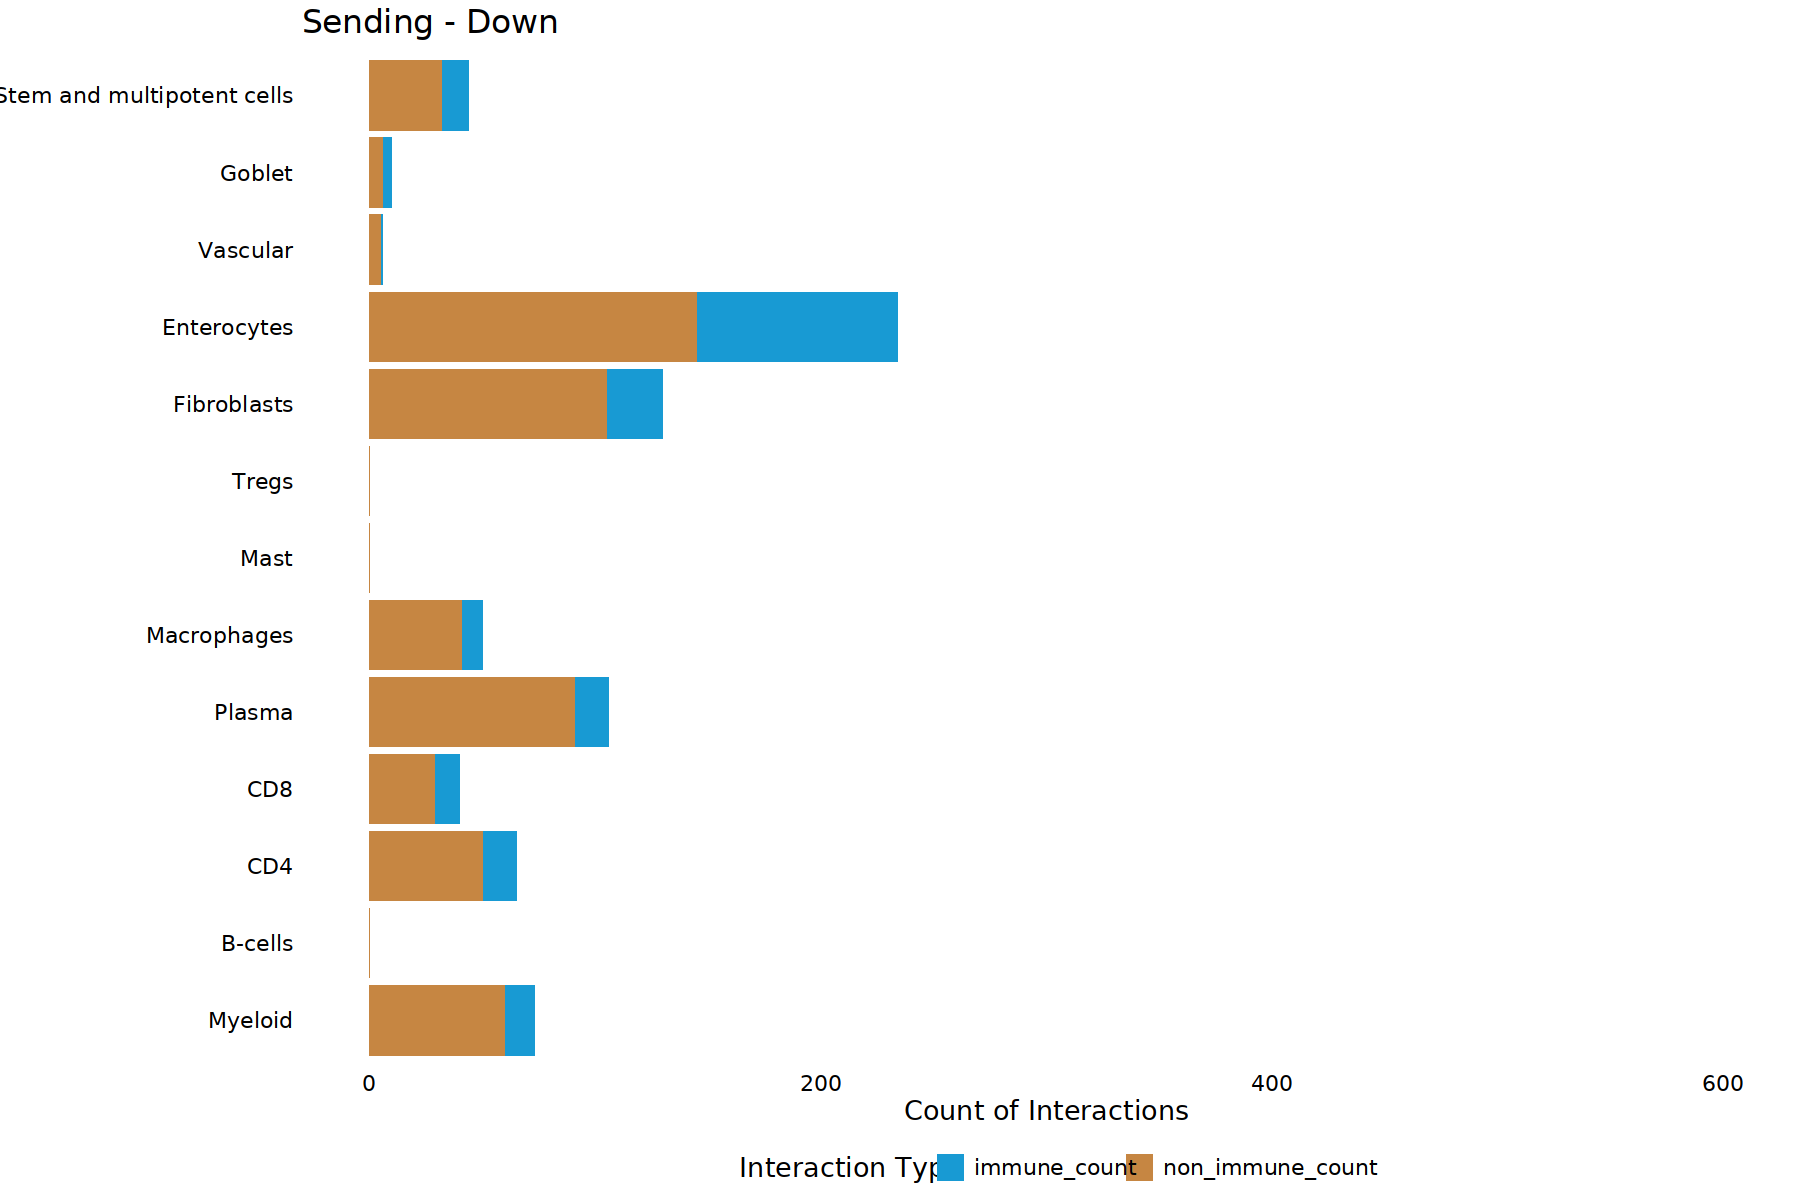

In [15]:
# Sending - Down
sending_down_total <- interactions$anno_interactions %>%
  filter(idx_down & idx_sign) %>%
  group_by(sending_cell_type) %>%
  summarise(total_count = n(), .groups = 'drop')

sending_down_immune <- interactions$anno_interactions %>%
  filter(idx_down & idx_sign & receiving_cell_type %in% immune_cell_types) %>%
  group_by(sending_cell_type) %>%
  summarise(immune_count = n(), .groups = 'drop')

sending_down_data <- merge(sending_down_total, sending_down_immune, by = "sending_cell_type", all.x = TRUE)
sending_down_data$immune_count[is.na(sending_down_data$immune_count)] <- 0
sending_down_data$non_immune_count <- sending_down_data$total_count - sending_down_data$immune_count

# Ensure all cell types are included, even those with zero interactions
sending_down_data_complete <- merge(data.frame(sending_cell_type = ordered_cell_types), sending_down_data, by = "sending_cell_type", all = TRUE)
sending_down_data_complete$immune_count[is.na(sending_down_data_complete$immune_count)] <- 0
sending_down_data_complete$non_immune_count[is.na(sending_down_data_complete$non_immune_count)] <- 0

sending_down_data_long <- tidyr::pivot_longer(sending_down_data_complete,
                                      cols = c("immune_count", "non_immune_count"),
                                      names_to = "interaction_type",
                                      values_to = "count")
sending_down_data_long$sending_cell_type <- factor(sending_down_data_long$sending_cell_type, levels = ordered_cell_types)

ggplot(sending_down_data_long, aes(x = sending_cell_type, y = count, fill = interaction_type)) +
  geom_bar(stat = "identity", position = "stack") +
  scale_fill_manual(values = c("non_immune_count" = '#c68642', "immune_count" = "#189ad3")) +
  coord_flip(ylim = c(0, 600)) +
  xlab("") +
  ylab("Count of Interactions") +
  ggtitle("Sending - Down") +
  theme_minimal() +
  theme(
    text = element_text(family = "Helvetica", size = 16),
    axis.text.x = element_text(size = 13, color = "black"),
    axis.text.y = element_text(size = 13, color = "black"),
    panel.grid.major = element_blank(),
    panel.grid.minor = element_blank(),
    legend.position = "bottom"
  ) +
  guides(fill = guide_legend(title = "Interaction Type"))

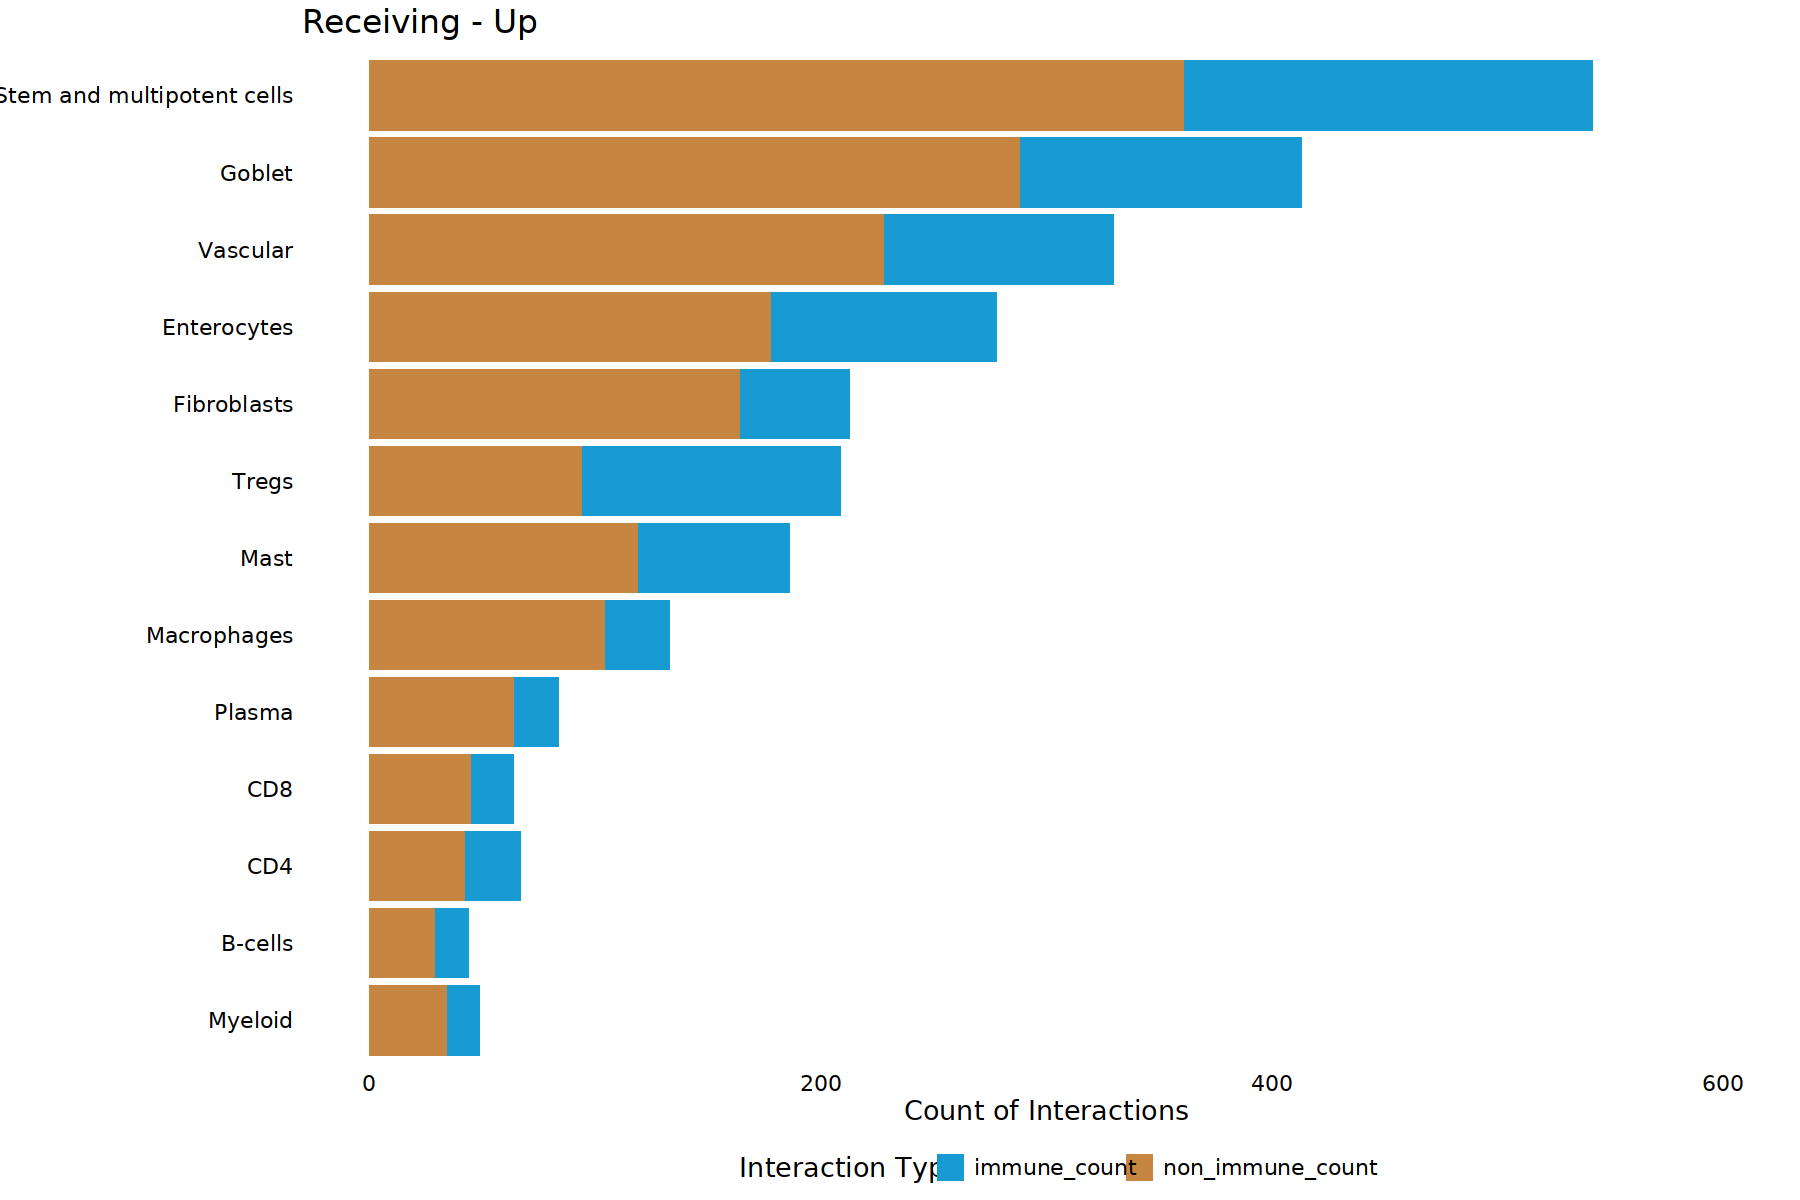

In [16]:
# Receiving - Up
receiving_up_total <- interactions$anno_interactions %>%
  filter(idx_up & idx_sign) %>%
  group_by(receiving_cell_type) %>%
  summarise(total_count = n(), .groups = 'drop')

receiving_up_immune <- interactions$anno_interactions %>%
  filter(idx_up & idx_sign & sending_cell_type %in% immune_cell_types) %>%
  group_by(receiving_cell_type) %>%
  summarise(immune_count = n(), .groups = 'drop')

receiving_up_data <- merge(receiving_up_total, receiving_up_immune, by = "receiving_cell_type", all.x = TRUE)
receiving_up_data$immune_count[is.na(receiving_up_data$immune_count)] <- 0
receiving_up_data$non_immune_count <- receiving_up_data$total_count - receiving_up_data$immune_count

# Ensure all cell types are included, even those with zero interactions
receiving_up_data_complete <- merge(data.frame(receiving_cell_type = ordered_cell_types), receiving_up_data, by = "receiving_cell_type", all = TRUE)
receiving_up_data_complete$immune_count[is.na(receiving_up_data_complete$immune_count)] <- 0
receiving_up_data_complete$non_immune_count[is.na(receiving_up_data_complete$non_immune_count)] <- 0

receiving_up_data_long <- tidyr::pivot_longer(receiving_up_data_complete,
                                      cols = c("immune_count", "non_immune_count"),
                                      names_to = "interaction_type",
                                      values_to = "count")
receiving_up_data_long$receiving_cell_type <- factor(receiving_up_data_long$receiving_cell_type, levels = ordered_cell_types)

ggplot(receiving_up_data_long, aes(x = receiving_cell_type, y = count, fill = interaction_type)) +
  geom_bar(stat = "identity", position = "stack") +
  scale_fill_manual(values = c("non_immune_count" = '#c68642', "immune_count" = "#189ad3")) +
  coord_flip(ylim = c(0, 600)) +
  xlab("") +
  ylab("Count of Interactions") +
  ggtitle("Receiving - Up") +
  theme_minimal() +
  theme(
    text = element_text(family = "Helvetica", size = 16),
    axis.text.x = element_text(size = 13, color = "black"),
    axis.text.y = element_text(size = 13, color = "black"),
    panel.grid.major = element_blank(),
    panel.grid.minor = element_blank(),
    legend.position = "bottom"
  ) +
  guides(fill = guide_legend(title = "Interaction Type"))

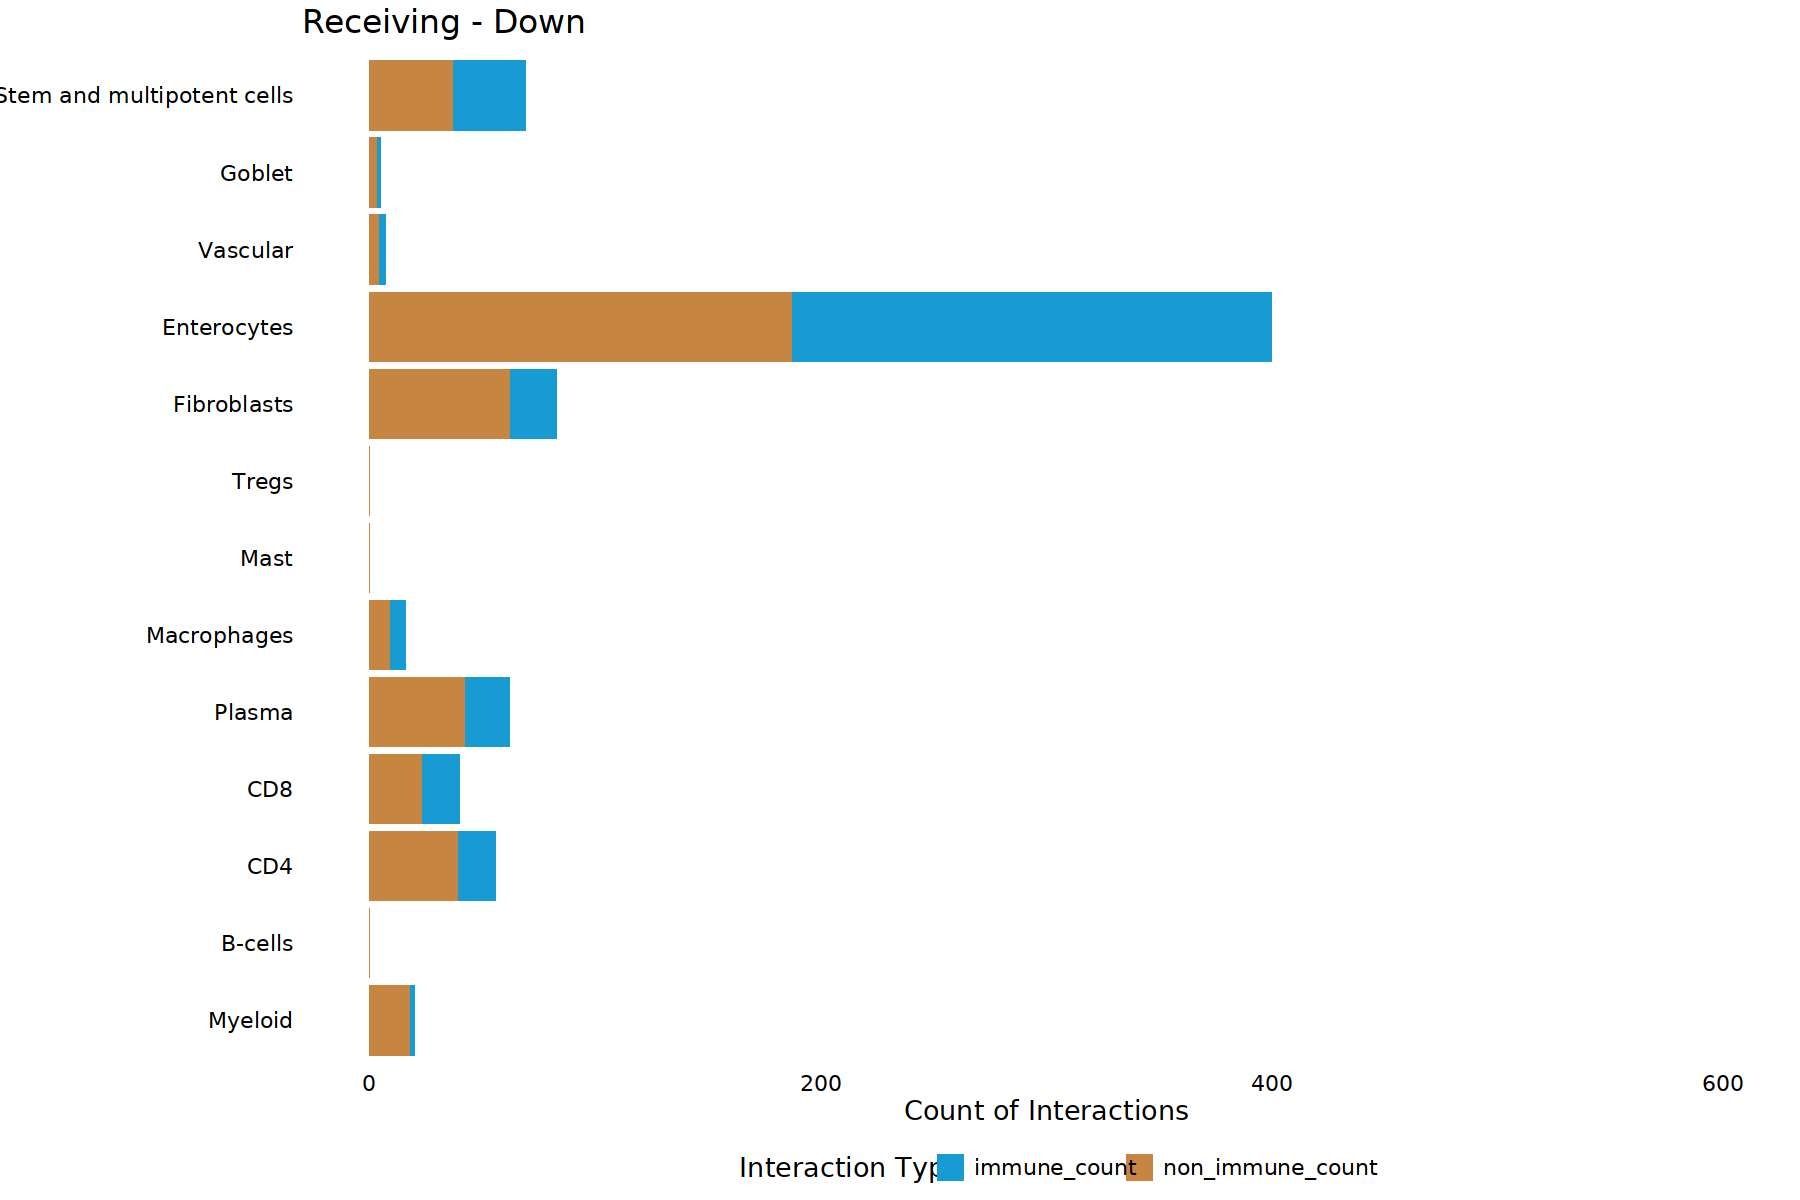

In [17]:
# Receiving - Down
receiving_down_total <- interactions$anno_interactions %>%
  filter(idx_down & idx_sign) %>%
  group_by(receiving_cell_type) %>%
  summarise(total_count = n(), .groups = 'drop')

receiving_down_immune <- interactions$anno_interactions %>%
  filter(idx_down & idx_sign & sending_cell_type %in% immune_cell_types) %>%
  group_by(receiving_cell_type) %>%
  summarise(immune_count = n(), .groups = 'drop')

receiving_down_data <- merge(receiving_down_total, receiving_down_immune, by = "receiving_cell_type", all.x = TRUE)
receiving_down_data$immune_count[is.na(receiving_down_data$immune_count)] <- 0
receiving_down_data$non_immune_count <- receiving_down_data$total_count - receiving_down_data$immune_count

# Ensure all cell types are included, even those with zero interactions
receiving_down_data_complete <- merge(data.frame(receiving_cell_type = ordered_cell_types), receiving_down_data, by = "receiving_cell_type", all = TRUE)
receiving_down_data_complete$immune_count[is.na(receiving_down_data_complete$immune_count)] <- 0
receiving_down_data_complete$non_immune_count[is.na(receiving_down_data_complete$non_immune_count)] <- 0

receiving_down_data_long <- tidyr::pivot_longer(receiving_down_data_complete,
                                      cols = c("immune_count", "non_immune_count"),
                                      names_to = "interaction_type",
                                      values_to = "count")
receiving_down_data_long$receiving_cell_type <- factor(receiving_down_data_long$receiving_cell_type, levels = ordered_cell_types)

ggplot(receiving_down_data_long, aes(x = receiving_cell_type, y = count, fill = interaction_type)) +
  geom_bar(stat = "identity", position = "stack") +
  scale_fill_manual(values = c("non_immune_count" = '#c68642', "immune_count" = "#189ad3")) +
  coord_flip(ylim = c(0, 600)) +
  xlab("") +
  ylab("Count of Interactions") +
  ggtitle("Receiving - Down") +
  theme_minimal() +
  theme(
    text = element_text(family = "Helvetica", size = 16),
    axis.text.x = element_text(size = 13, color = "black"),
    axis.text.y = element_text(size = 13, color = "black"),
    panel.grid.major = element_blank(),
    panel.grid.minor = element_blank(),
    legend.position = "bottom"
  ) +
  guides(fill = guide_legend(title = "Interaction Type"))

# Suppl. Figure 4b

[1] "Gene: CD44 - Number of interactions: 240"


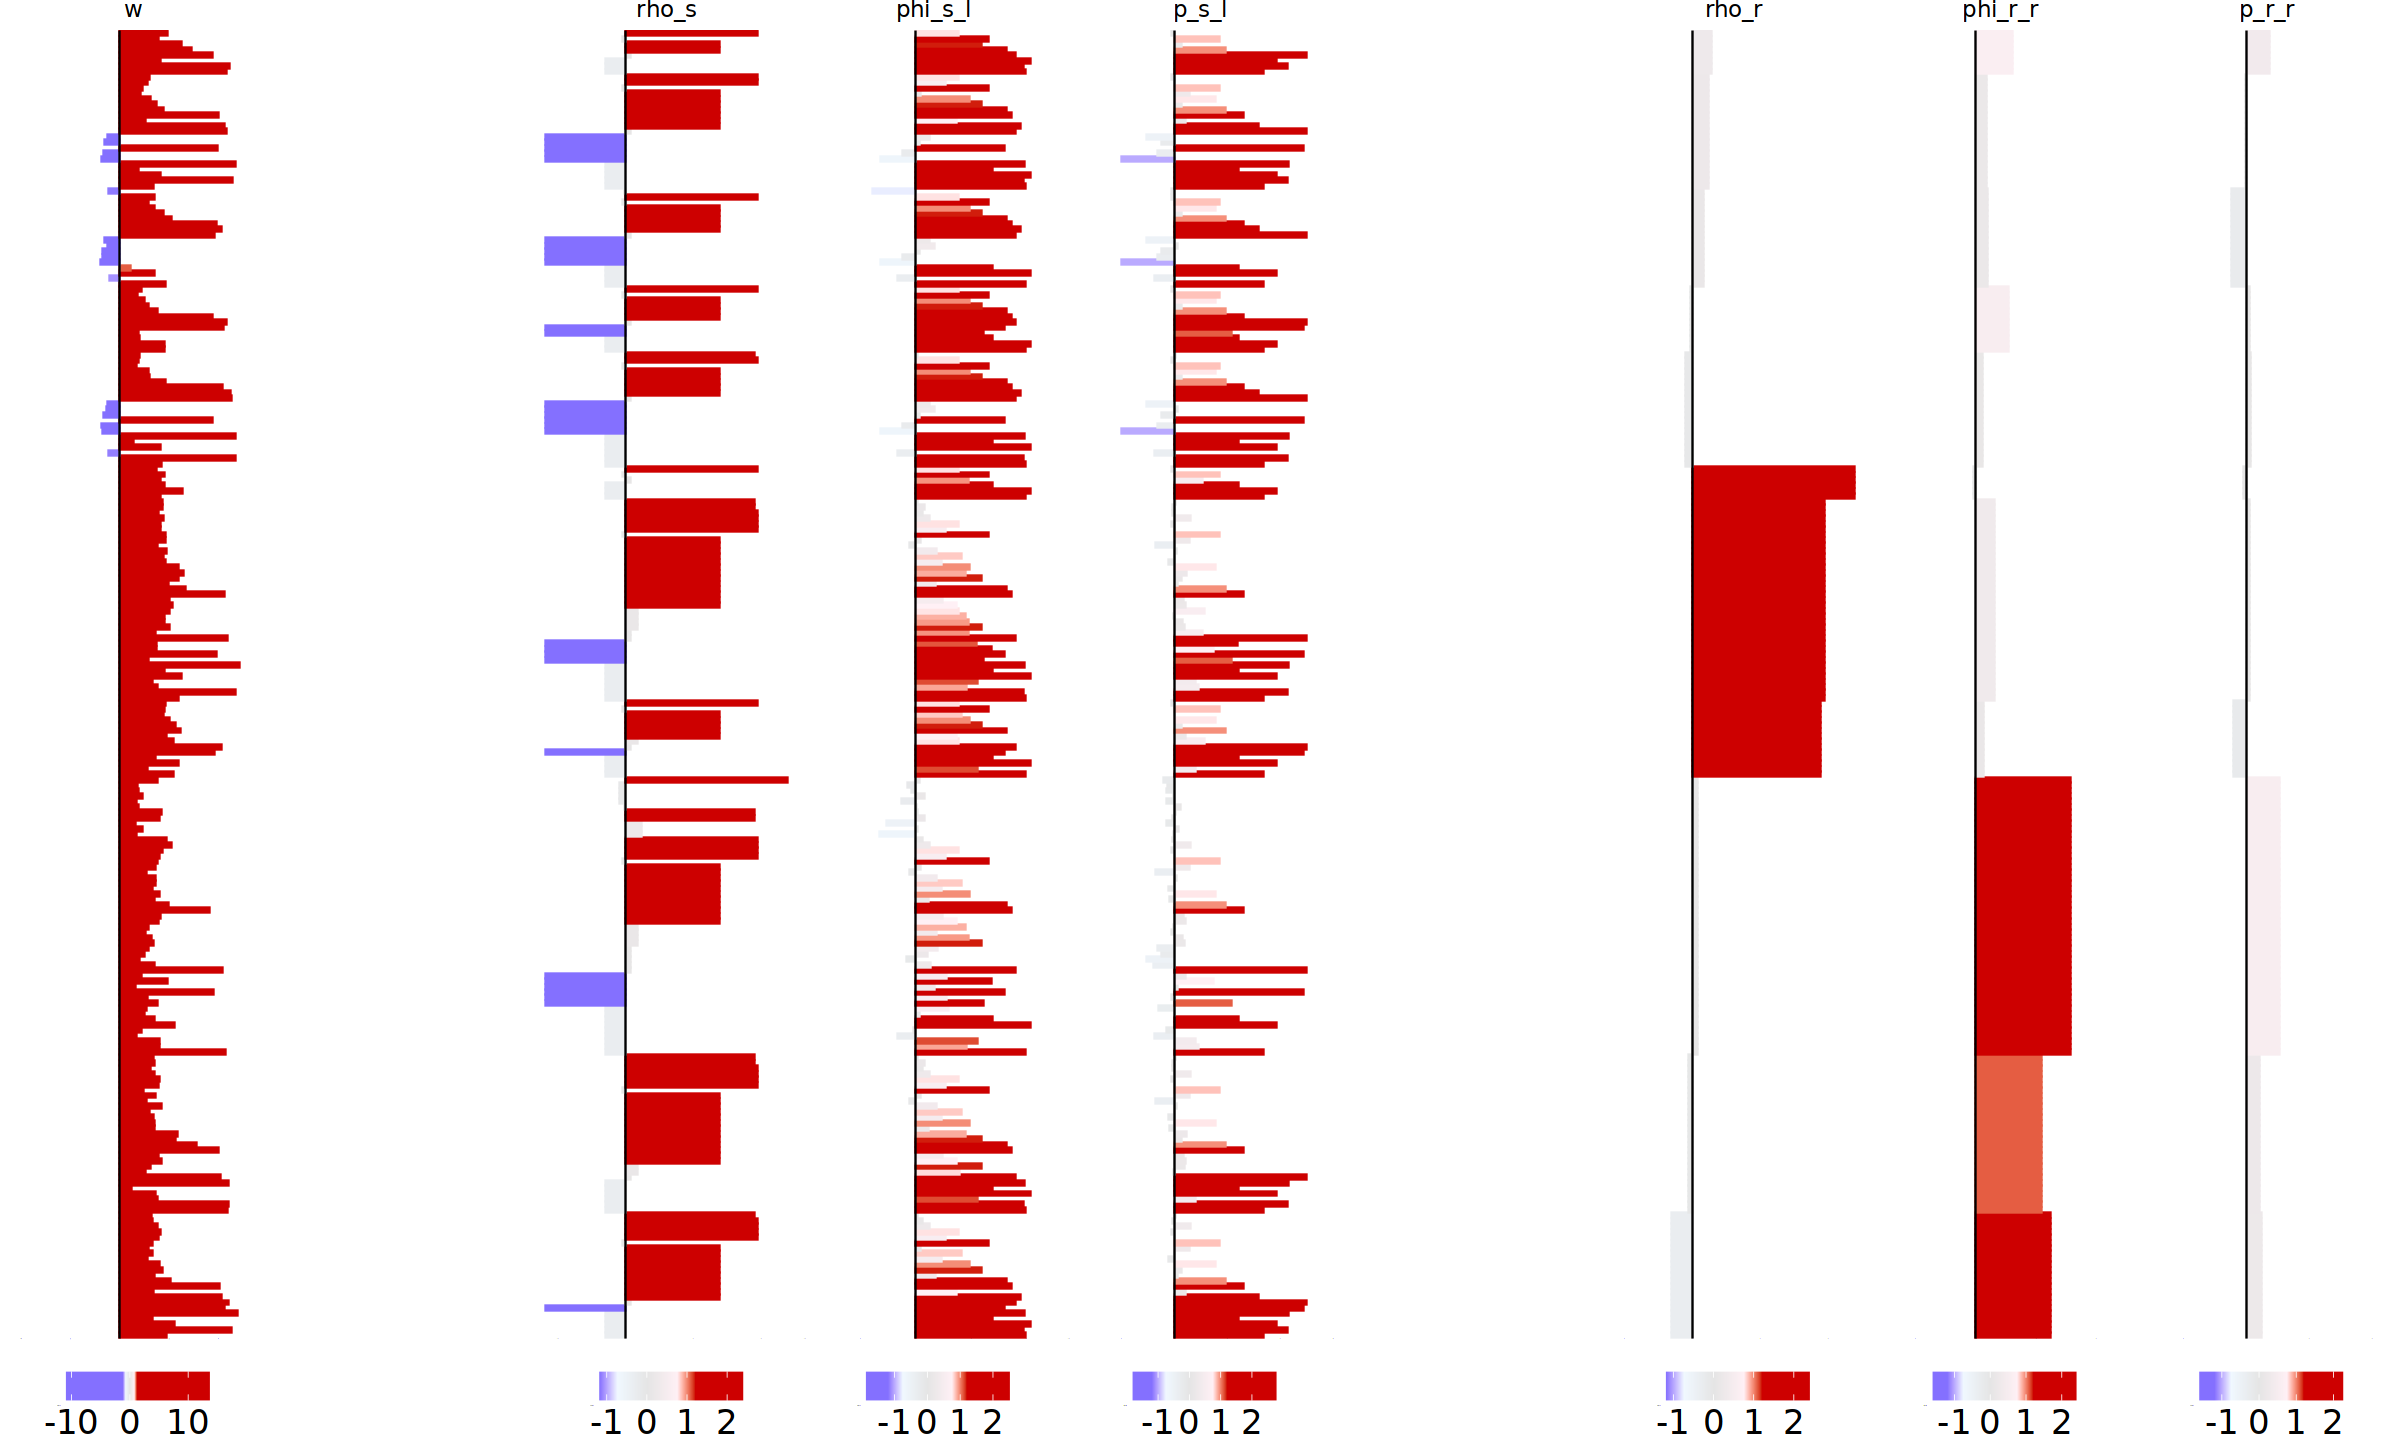

In [18]:
options(repr.plot.width = 20, repr.plot.height = 12)
receiving_genes <- c("CD44")

for (gene in receiving_genes) {
  my_anno_interactions <- interactions$anno_interactions[
    interactions$anno_interactions$receptor_gene_name == gene &
      interactions$anno_interactions$interaction_ID %in% IDs,
  ]

  interaction_count <- nrow(my_anno_interactions)

  if (interaction_count > 0) {
    # Number of receiver-side parameters changing
    my_anno_interactions$num_params_changing <- rowSums(
      abs(my_anno_interactions[, c("log2FC_rho_r_direction", "log2FC_phi_r_r_direction", "log2FC_p_r_r_direction")]) > 0
    )

    # Interactions with changes first (sorted by rho direction, then rho log2FC), then unchanged
    interactions_zero <- my_anno_interactions[my_anno_interactions$num_params_changing == 0, ]
    interactions_with_changes <- my_anno_interactions[my_anno_interactions$num_params_changing > 0, ]

    interactions_with_changes <- interactions_with_changes[order(
        interactions_with_changes$log2FC_rho_r_direction > 0,
        interactions_with_changes$log2FC_rho_r_direction < 0,
        interactions_with_changes$log2FC_rho_r
    ), ]
    interactions_zero <- interactions_zero[order(interactions_zero$log2FC_rho_r), ]

    my_anno_interactions <- rbind(interactions_with_changes, interactions_zero)

    print(paste("Gene:", gene, "- Number of interactions:", interaction_count))

    plot_all_forests(
      my_idx = rep(TRUE, nrow(my_anno_interactions)),
      my_anno_interactions = my_anno_interactions,
      keep_order = TRUE,
      threshold = 1,
      legend_title_size = 0,
      legend_text_size = 20,
      component_lim = component_lim
    )
  }
}

# Suppl. Figure 4d

[1] "Interaction: Stem and multipotent cells:VEGFA_Vascular:FLT1 - Number of interactions: 1"


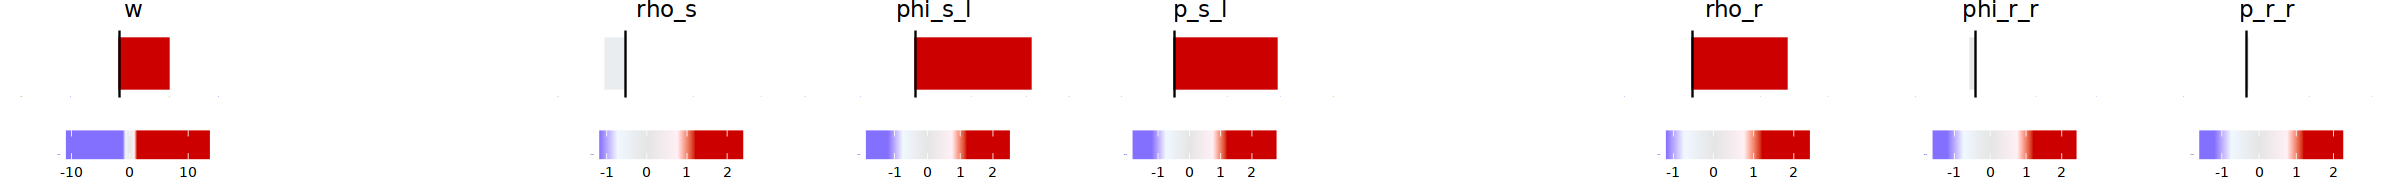

In [19]:
options(repr.plot.height = 1.5, repr.plot.width = 20)
my_interaction <- "Stem and multipotent cells:VEGFA_Vascular:FLT1"

my_anno_interactions <- interactions$anno_interactions[
  interactions$anno_interactions$interaction_ID == my_interaction &
  interactions$anno_interactions$interaction_ID %in% IDs,
]

interaction_count <- nrow(my_anno_interactions)

if (interaction_count > 0) {
    my_anno_interactions$interaction_ID <- factor(my_anno_interactions$interaction_ID, levels = my_interaction, ordered = TRUE)

    print(paste("Interaction:", my_interaction, "- Number of interactions:", interaction_count))

    plot_all_forests(
      my_idx = rep(TRUE, interaction_count),
      my_anno_interactions = my_anno_interactions,
      keep_order = TRUE,
      threshold = 1,
      legend_title_size = 0,
      legend_text_size = 8,
      component_lim = component_lim
    )
} else {
    print(paste("No interactions found for:", my_interaction))
}

[1] "Interaction: Stem and multipotent cells:VEGFA_Vascular:KDR - Number of interactions: 1"


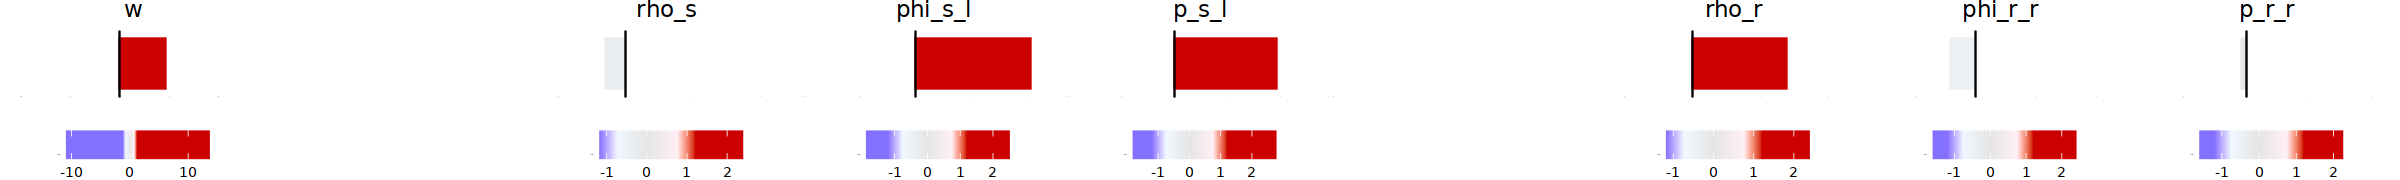

In [20]:
my_interaction <- "Stem and multipotent cells:VEGFA_Vascular:KDR"

my_anno_interactions <- interactions$anno_interactions[
  interactions$anno_interactions$interaction_ID == my_interaction &
  interactions$anno_interactions$interaction_ID %in% IDs,
]

interaction_count <- nrow(my_anno_interactions)

if (interaction_count > 0) {
    my_anno_interactions$interaction_ID <- factor(my_anno_interactions$interaction_ID, levels = my_interaction, ordered = TRUE)

    print(paste("Interaction:", my_interaction, "- Number of interactions:", interaction_count))

    plot_all_forests(
      my_idx = rep(TRUE, interaction_count),
      my_anno_interactions = my_anno_interactions,
      keep_order = TRUE,
      threshold = 1,
      legend_title_size = 0,
      legend_text_size = 8,
      component_lim = component_lim
    )
} else {
    print(paste("No interactions found for:", my_interaction))
}

# Suppl. Figure 5a

[1] "Cell Type: Stem and multipotent cells - Number of interactions: 580"
[1] "Cell Type: Enterocytes - Number of interactions: 489"


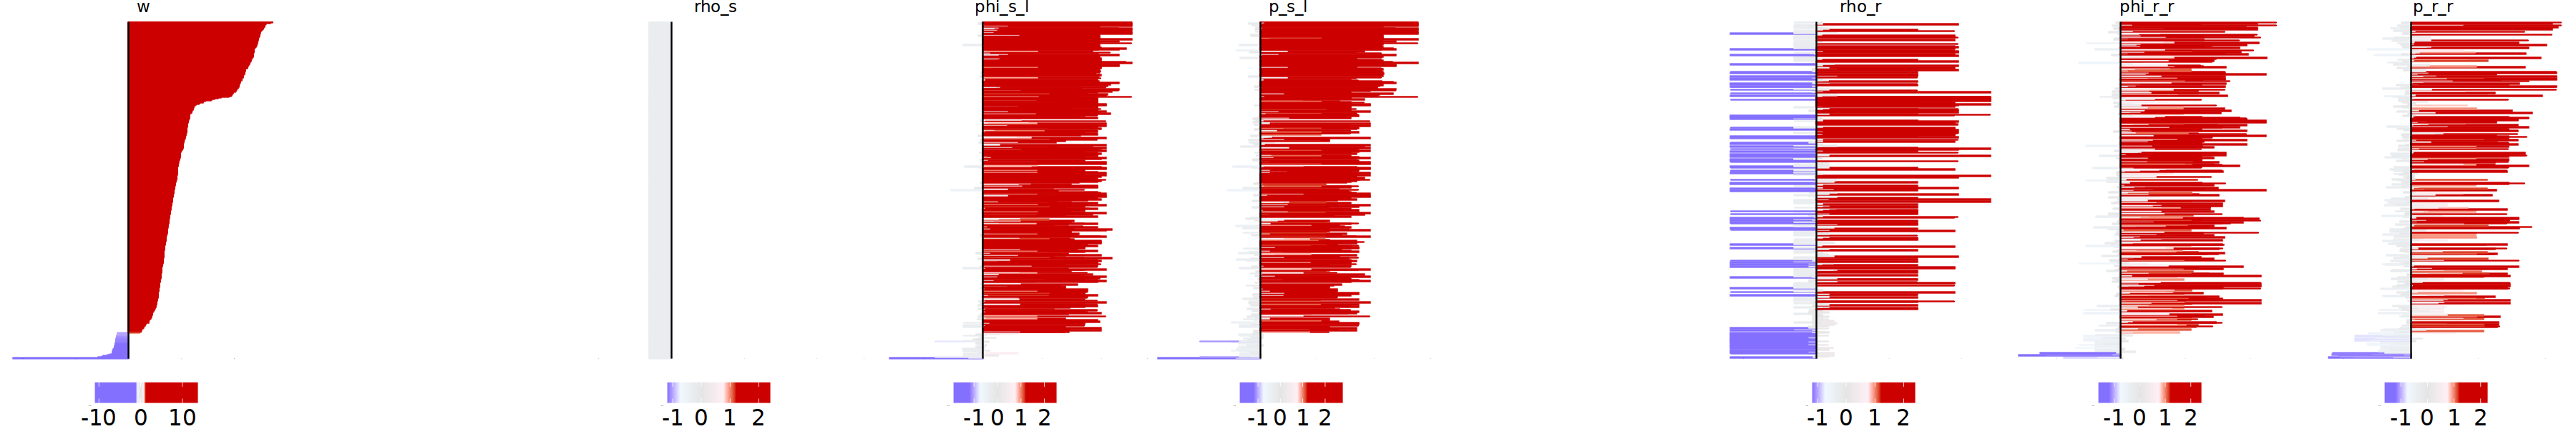

[1] "Cell Type: Goblet - Number of interactions: 328"


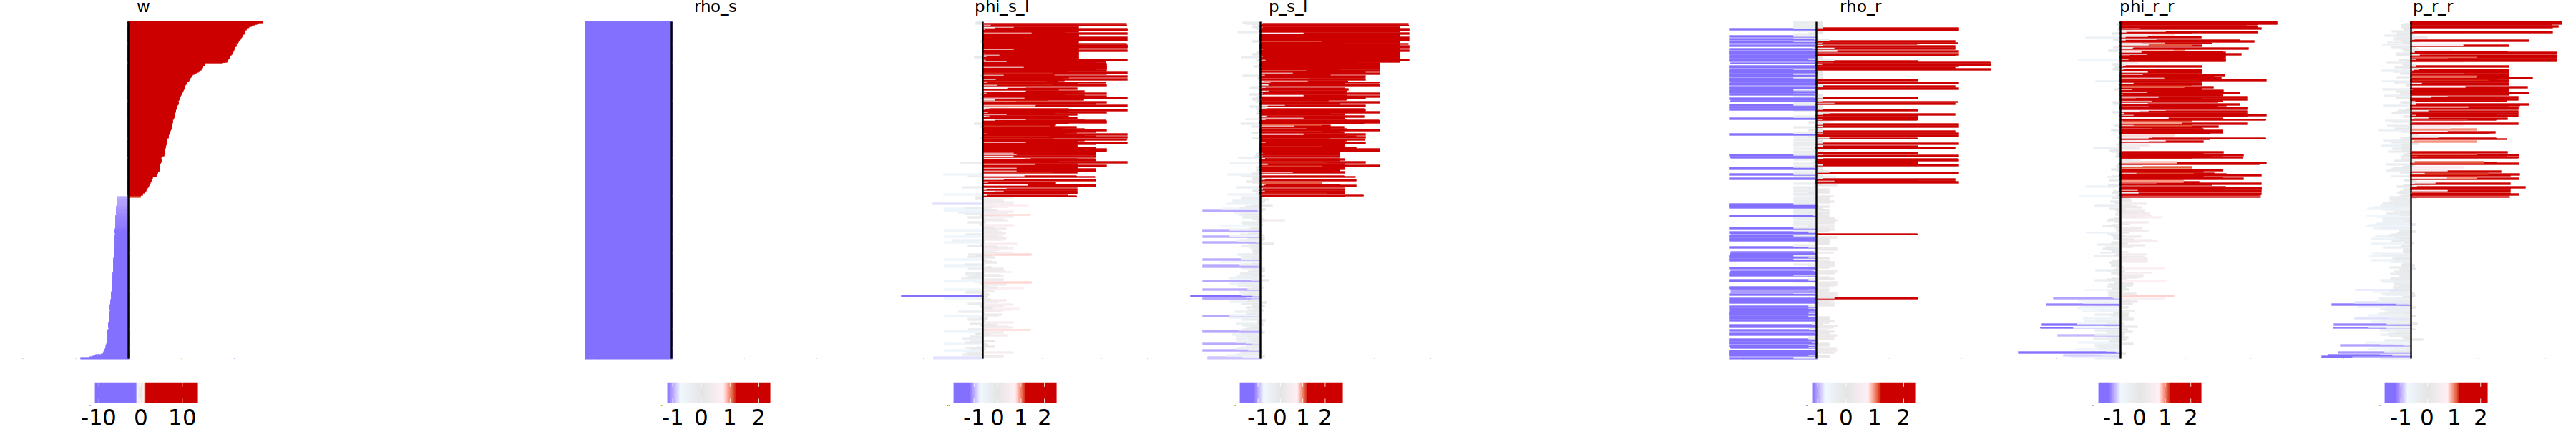

[1] "Cell Type: Fibroblasts - Number of interactions: 417"


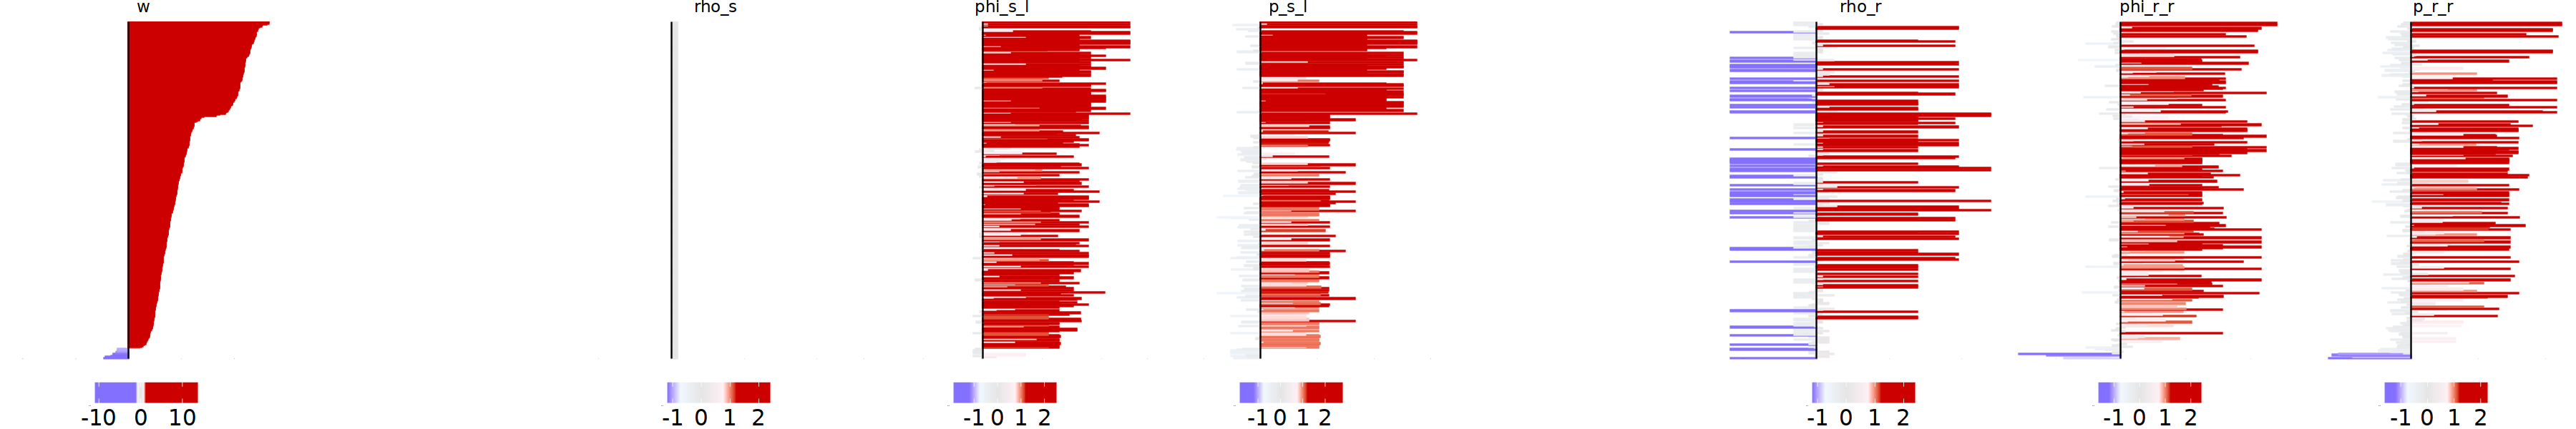

[1] "Cell Type: Vascular - Number of interactions: 360"


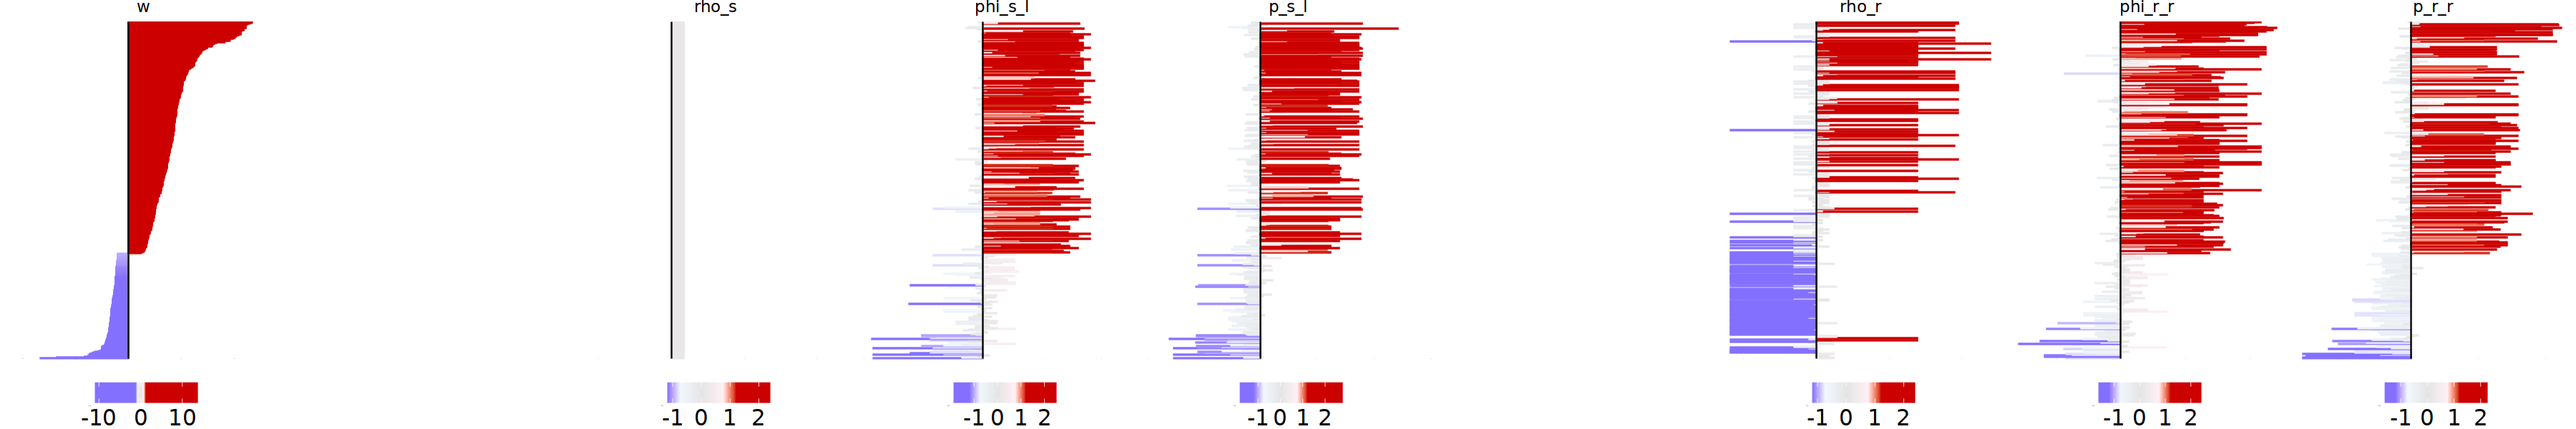

[1] "Cell Type: Macrophages - Number of interactions: 180"


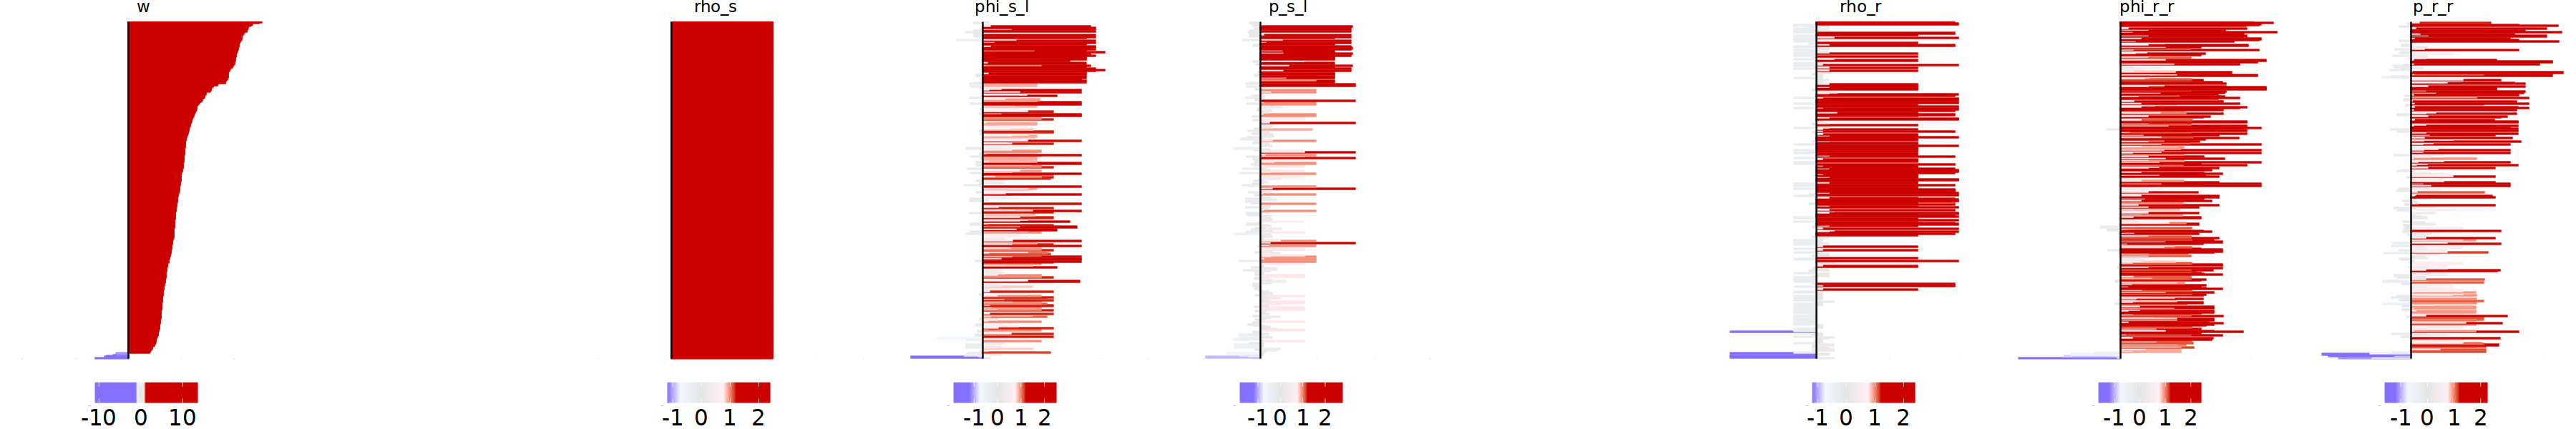

[1] "Cell Type: Myeloid - Number of interactions: 138"


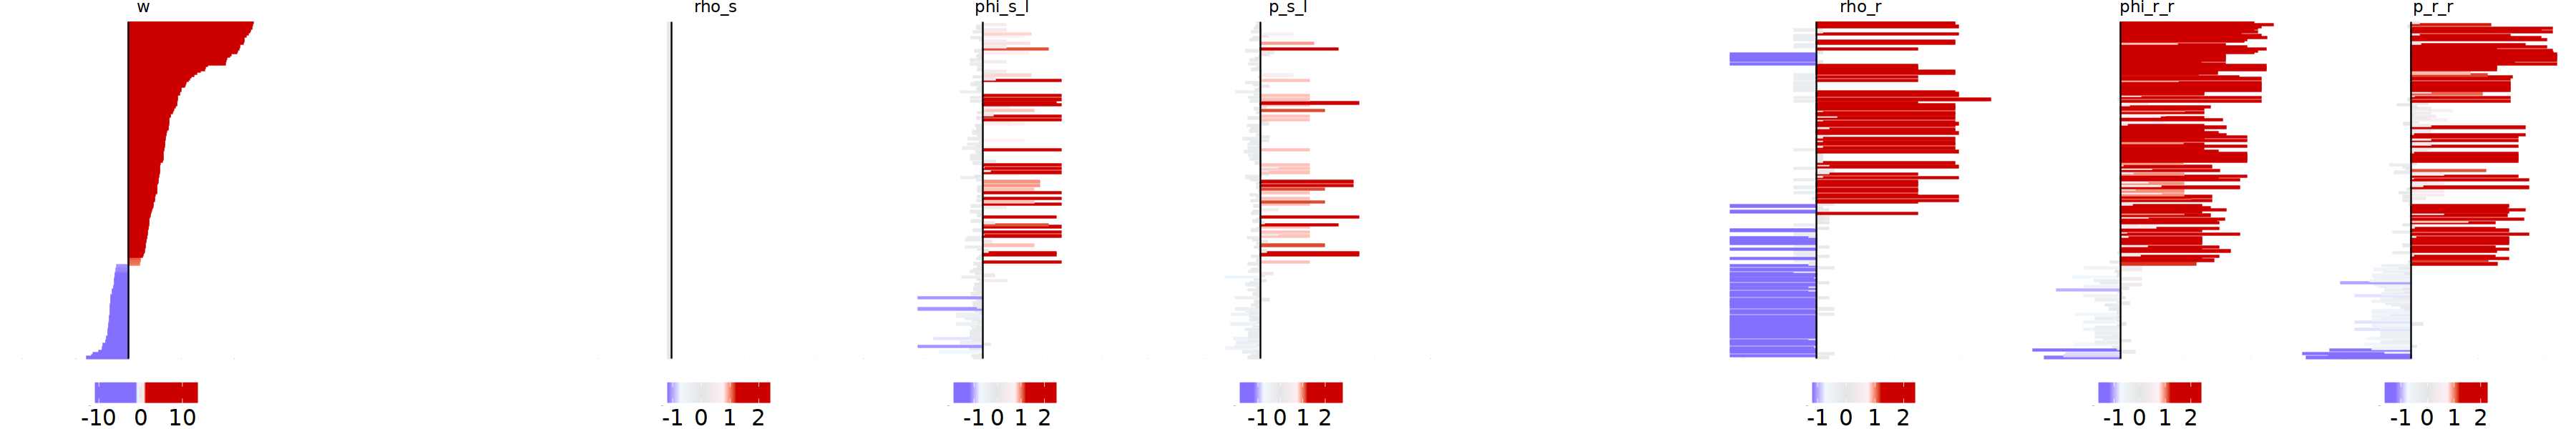

[1] "Cell Type: Mast - Number of interactions: 181"


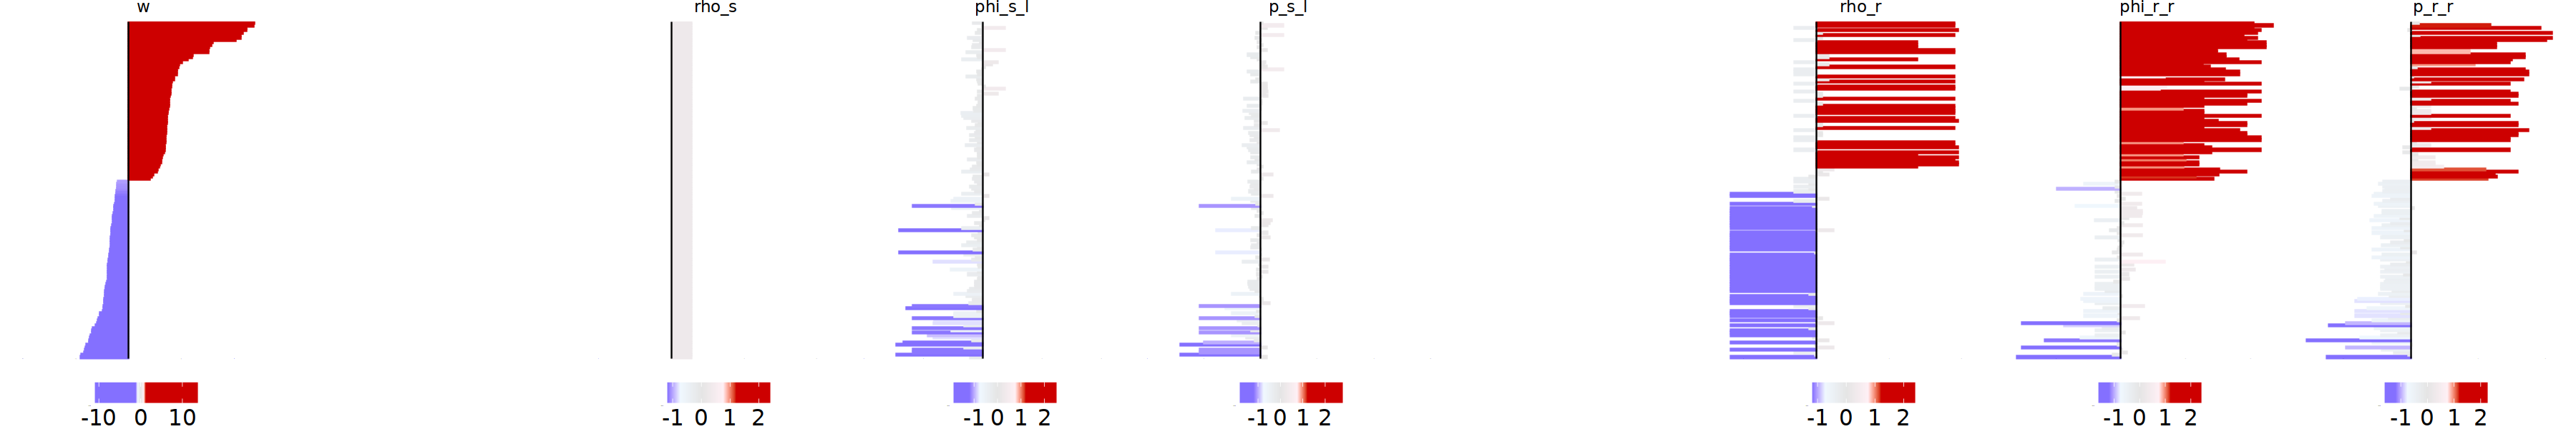

[1] "Cell Type: CD4 - Number of interactions: 125"


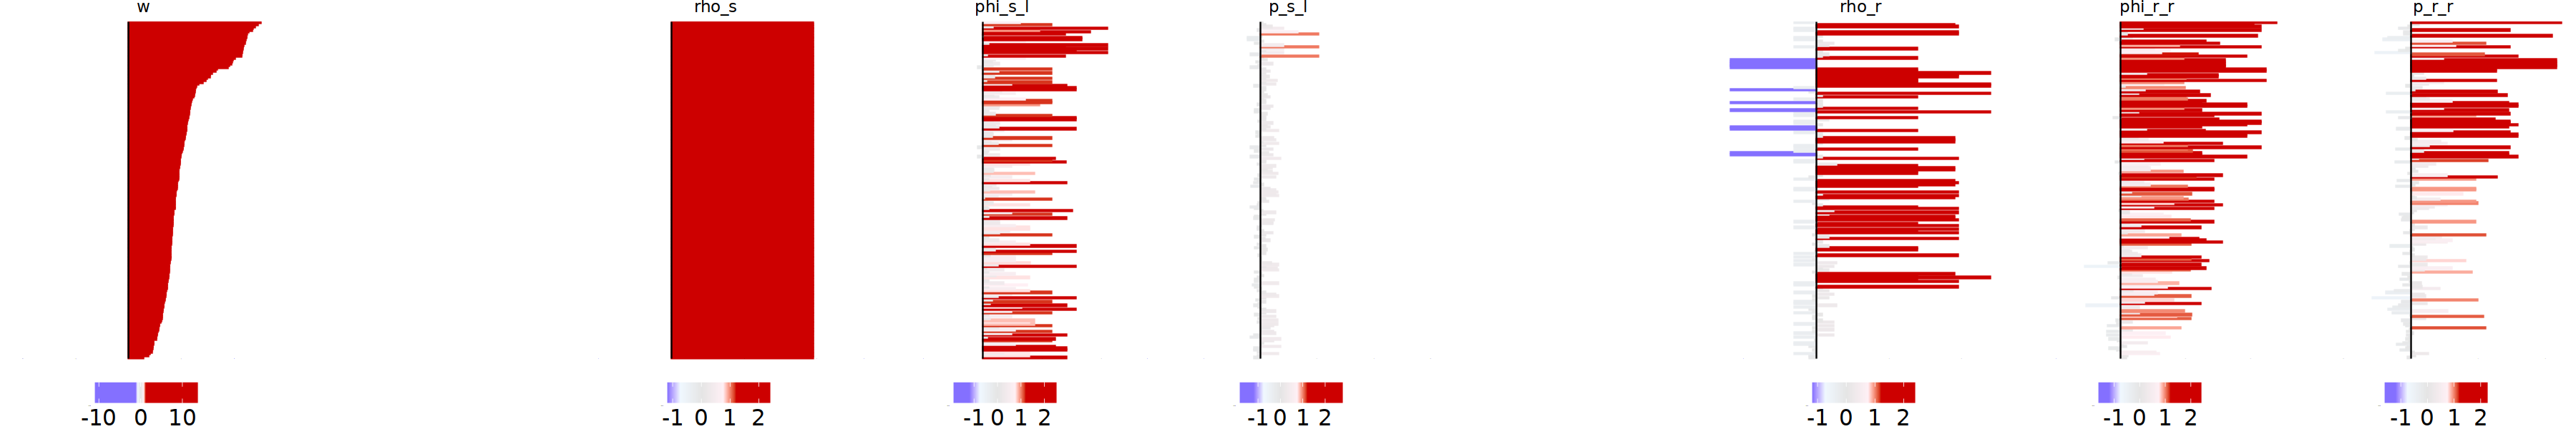

[1] "Cell Type: Tregs - Number of interactions: 175"


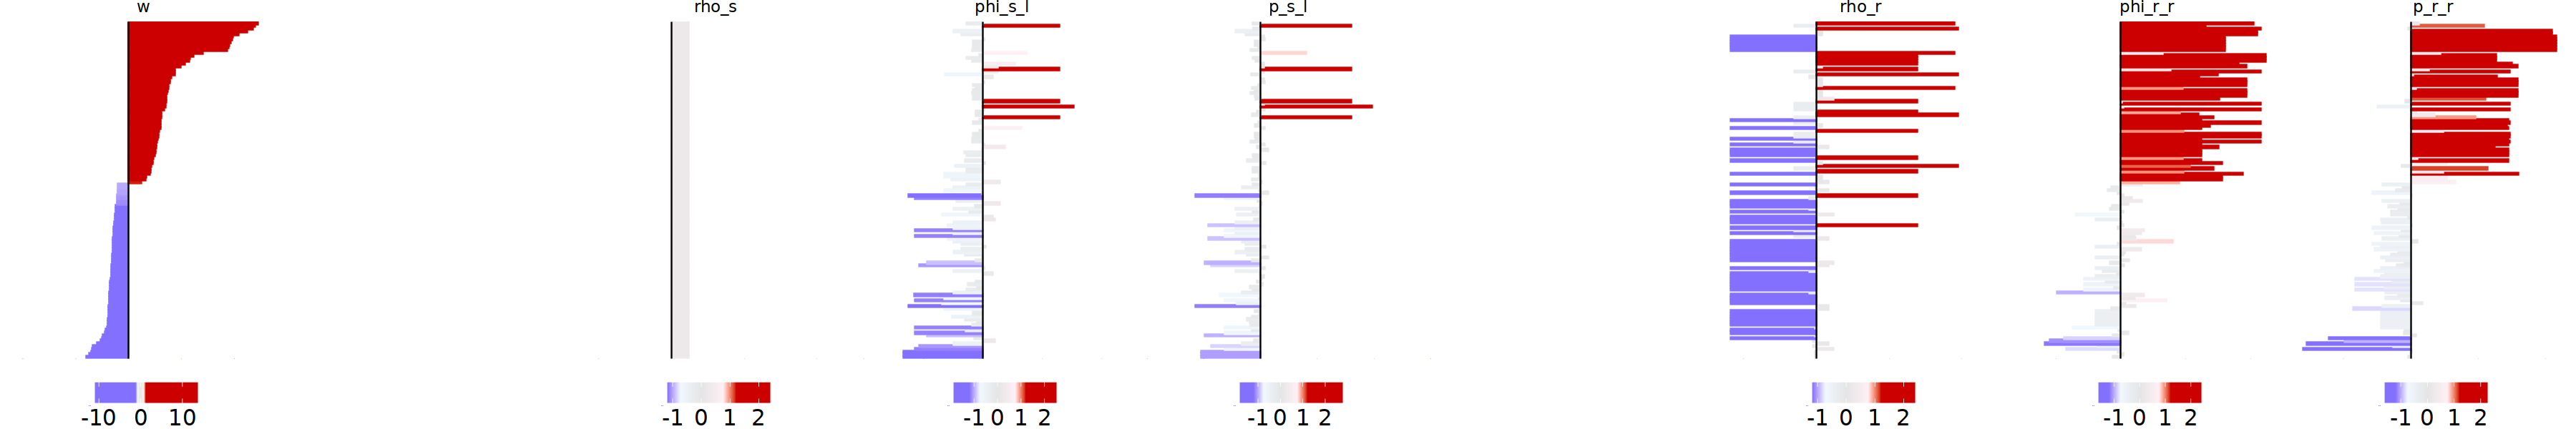

[1] "Cell Type: CD8 - Number of interactions: 108"


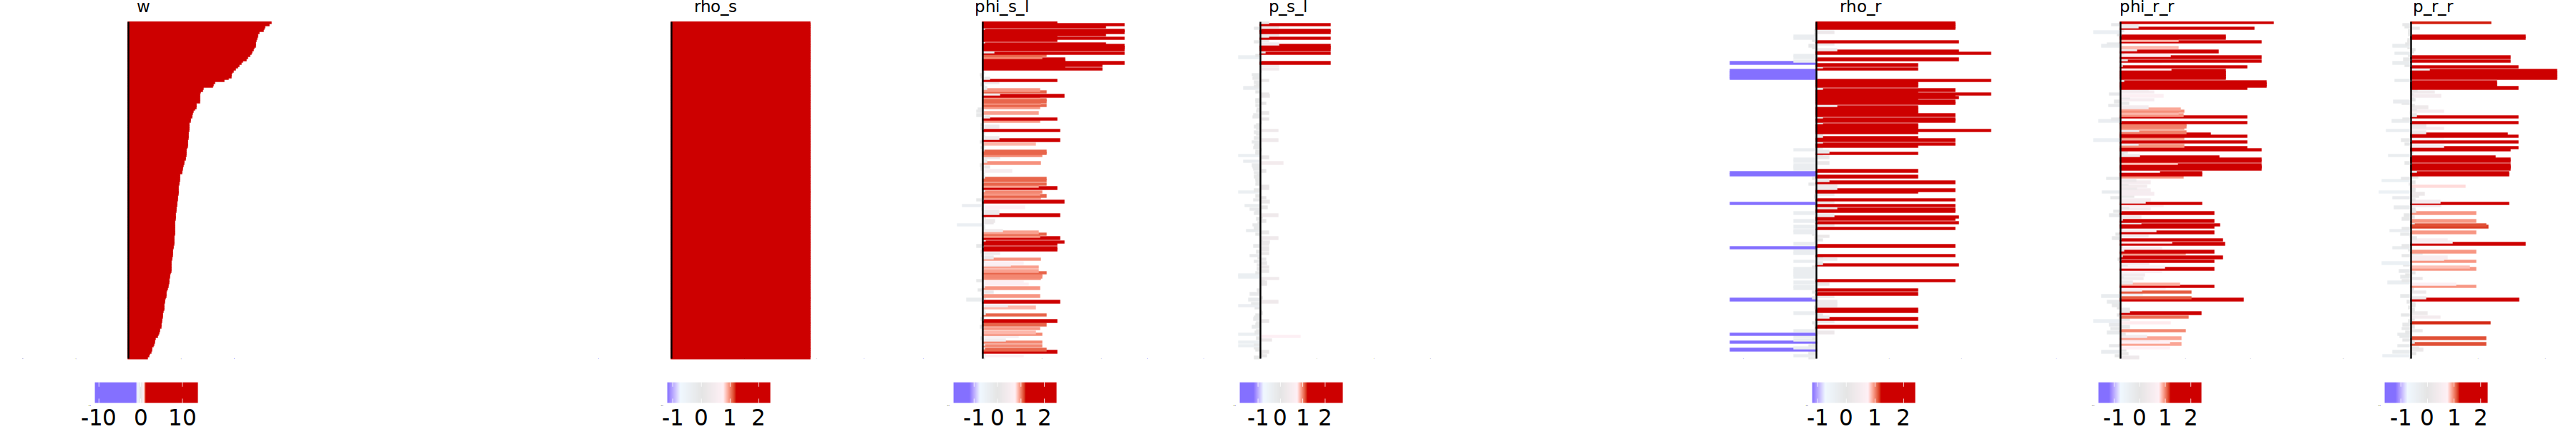

[1] "Cell Type: Plasma - Number of interactions: 213"


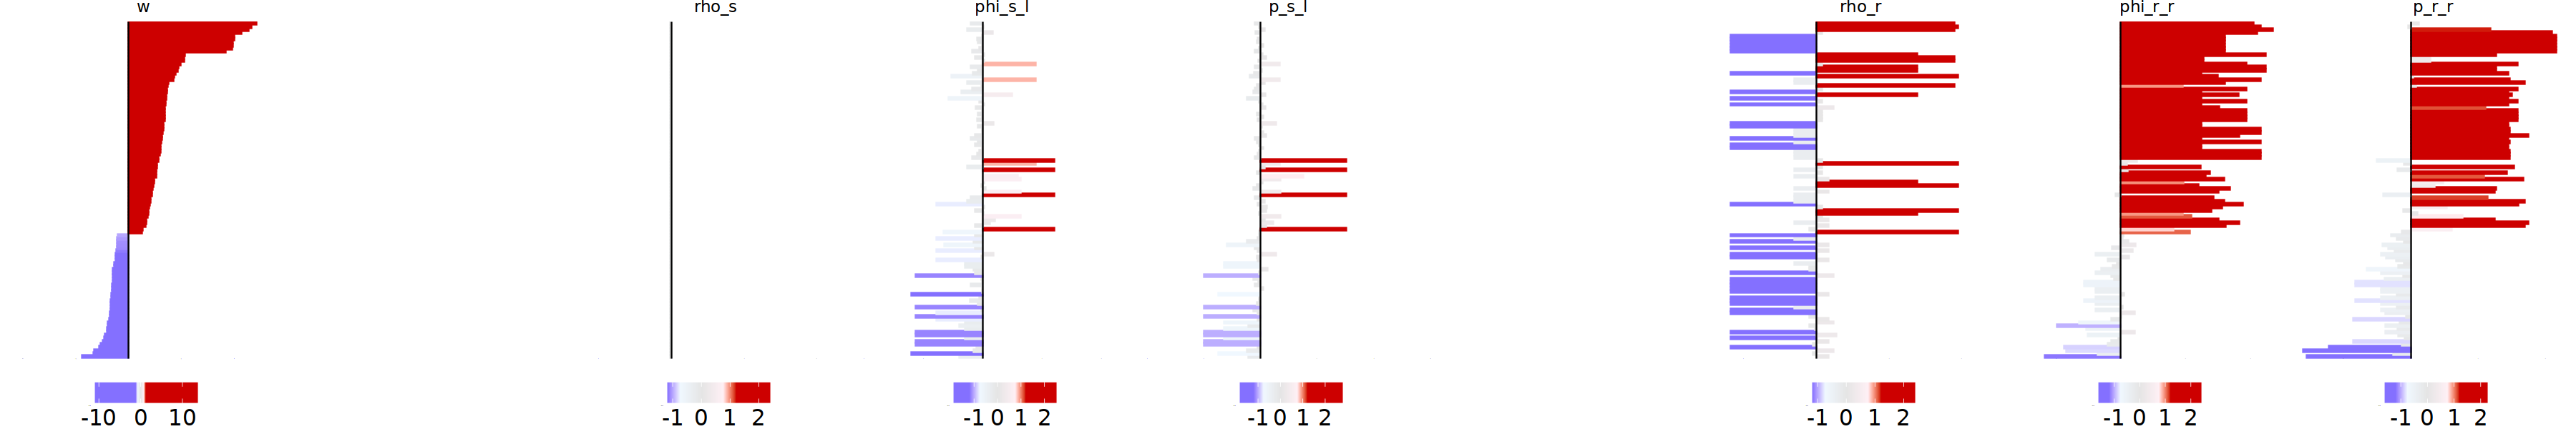

[1] "Cell Type: B-cells - Number of interactions: 76"


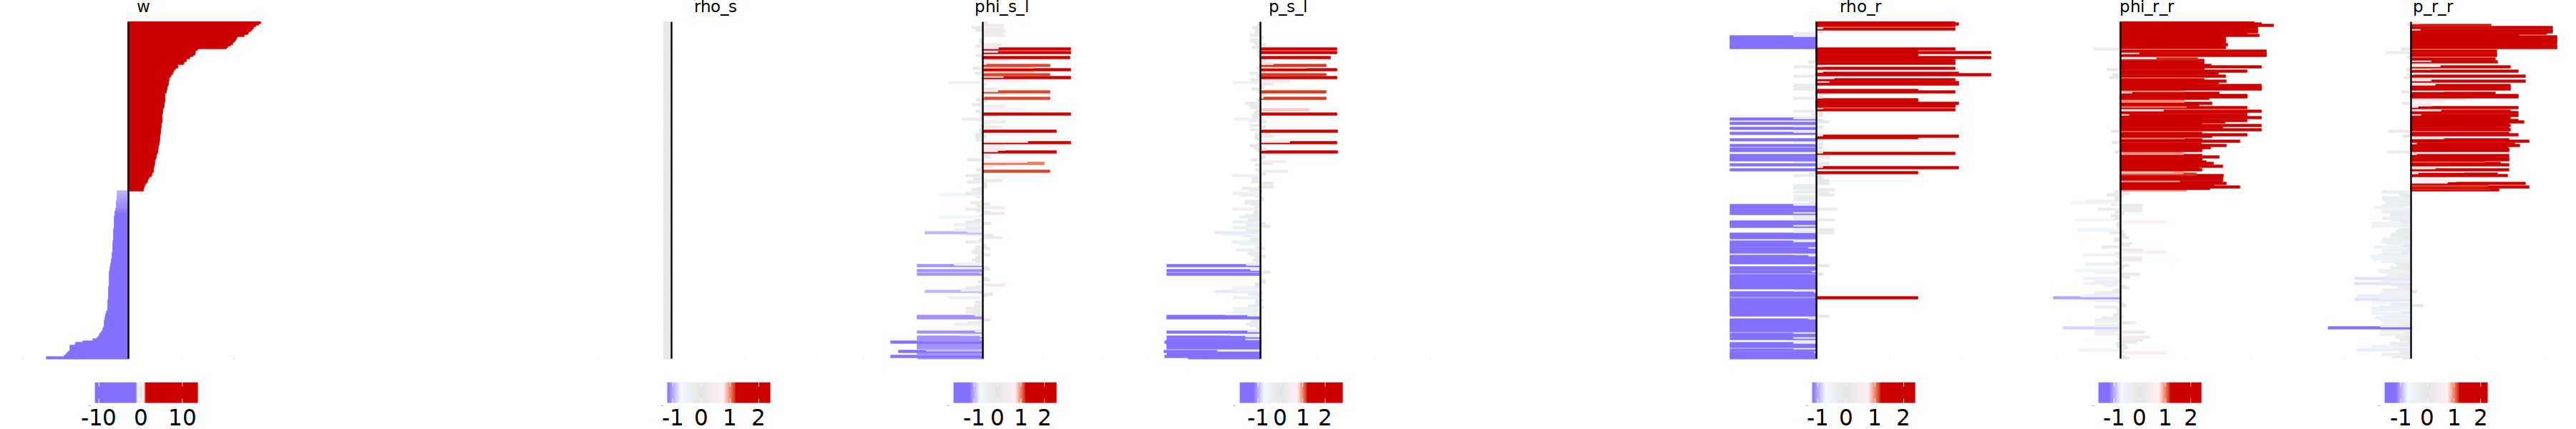

[1] "Total number of interactions across all sending cell types: 3370"


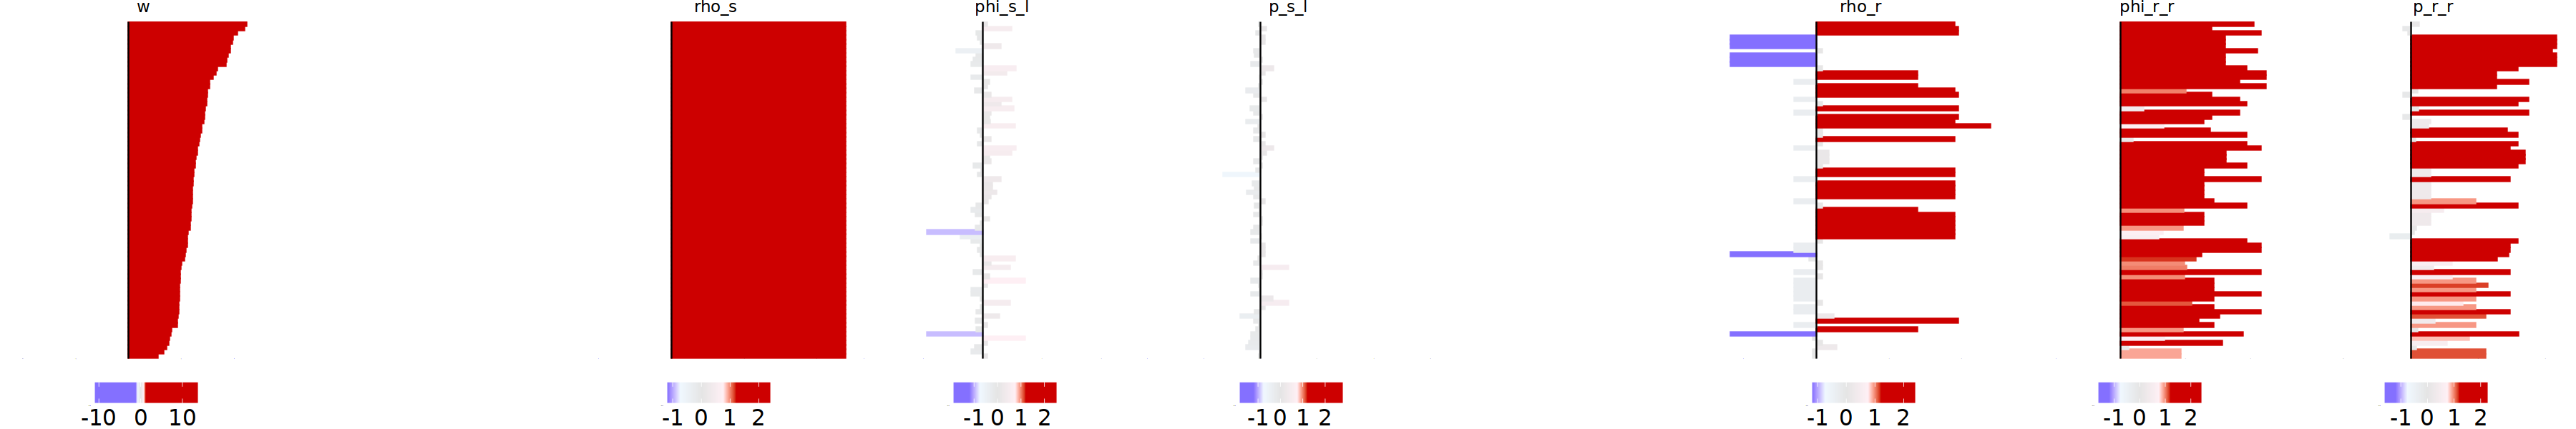

In [21]:
options(repr.plot.width = 30, repr.plot.height = 5)
sending_cell_types <- unique(interactions$anno_interactions$sending_cell_type)

total_interaction_count_sending <- 0

for(cell_type in sending_cell_types) {
    my_anno_interactions <- interactions$anno_interactions[interactions$anno_interactions$sending_cell_type == cell_type & interactions$anno_interactions$interaction_ID %in% IDs, ]

    interaction_count <- nrow(my_anno_interactions)

    if(interaction_count > 0) {
        my_anno_interactions <- my_anno_interactions[order(my_anno_interactions$log2FC_weights), ]

        total_interaction_count_sending <- total_interaction_count_sending + interaction_count

        print(paste("Cell Type:", cell_type, "- Number of interactions:", interaction_count))

        plot_all_forests(my_idx = rep(TRUE, interaction_count),
                         my_anno_interactions = my_anno_interactions,
                         keep_order = TRUE,
                         threshold = 1,
                         legend_title_size = 0,
                         legend_text_size = 18,
                         component_lim = component_lim
                        )
    }
}
print(paste("Total number of interactions across all sending cell types:", total_interaction_count_sending))

# Suppl. Figure 5b

[1] "Cell Type: Stem and multipotent cells - Number of interactions: 611"
[1] "Cell Type: Enterocytes - Number of interactions: 678"


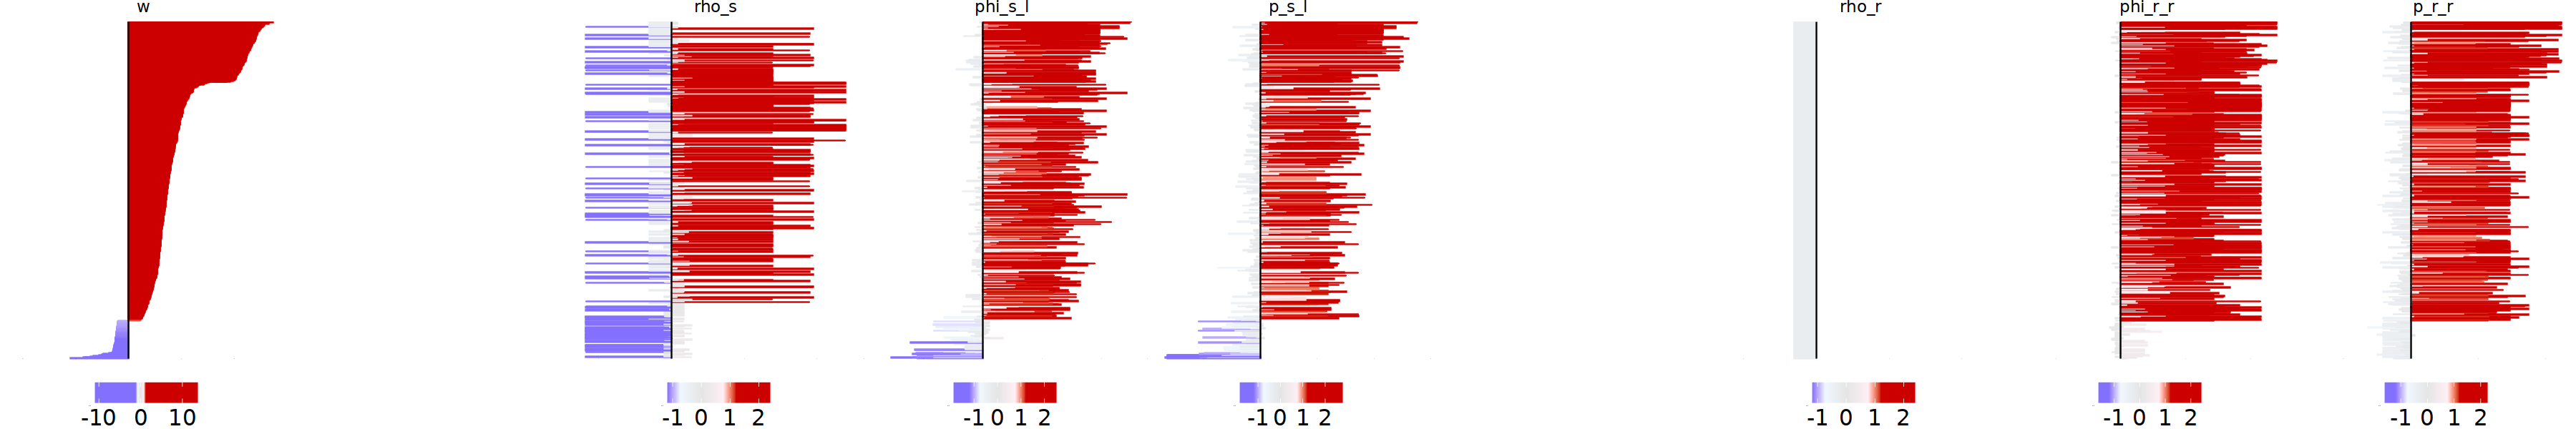

[1] "Cell Type: Goblet - Number of interactions: 418"


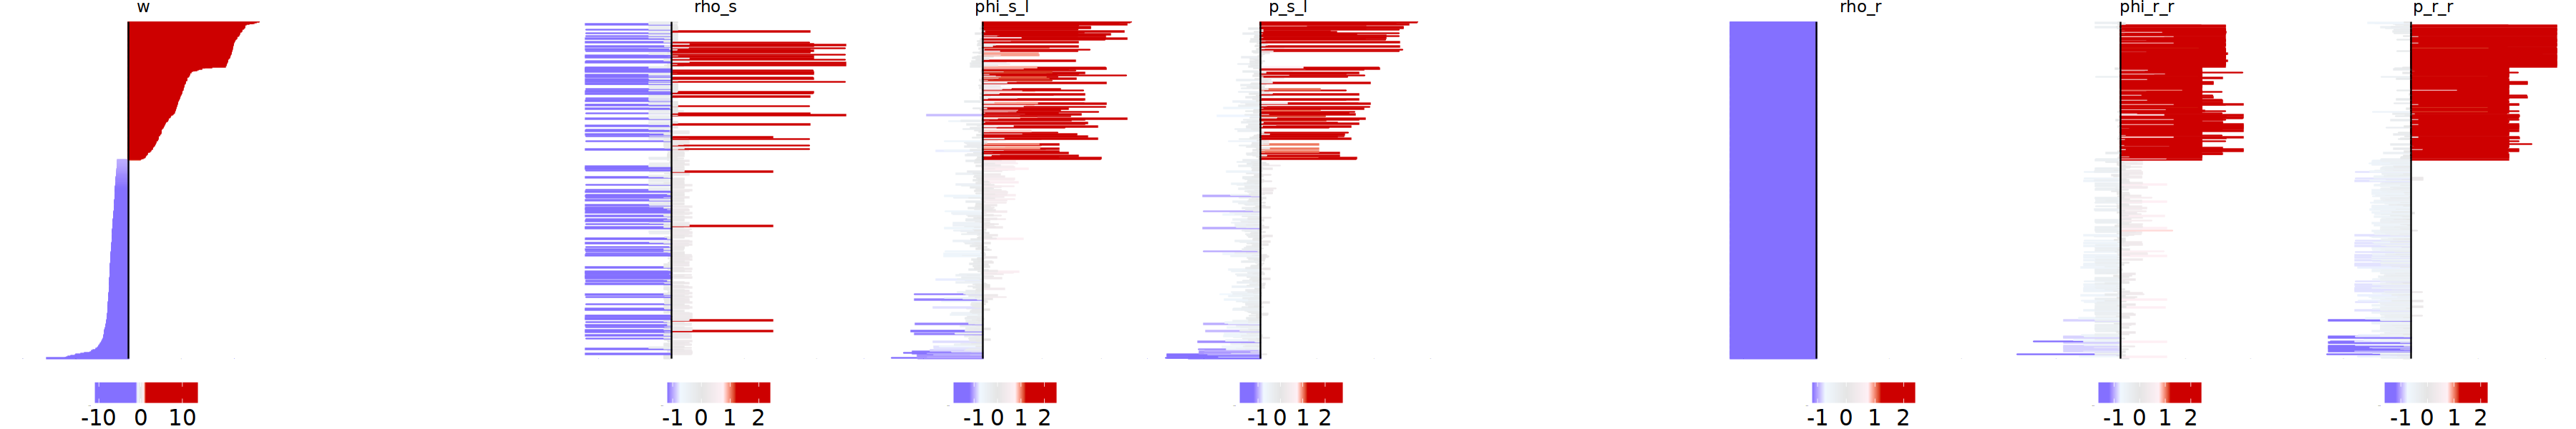

[1] "Cell Type: Fibroblasts - Number of interactions: 296"


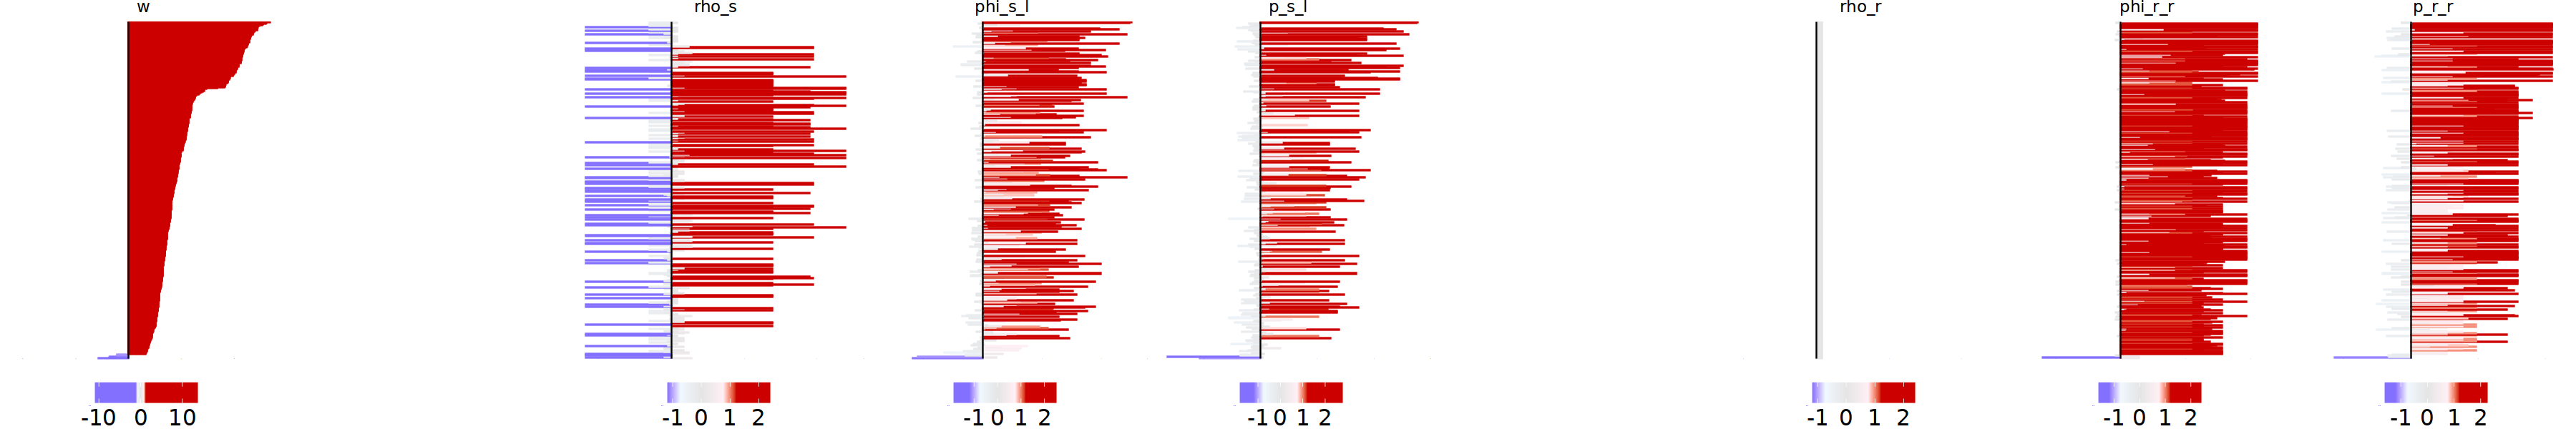

[1] "Cell Type: Vascular - Number of interactions: 337"


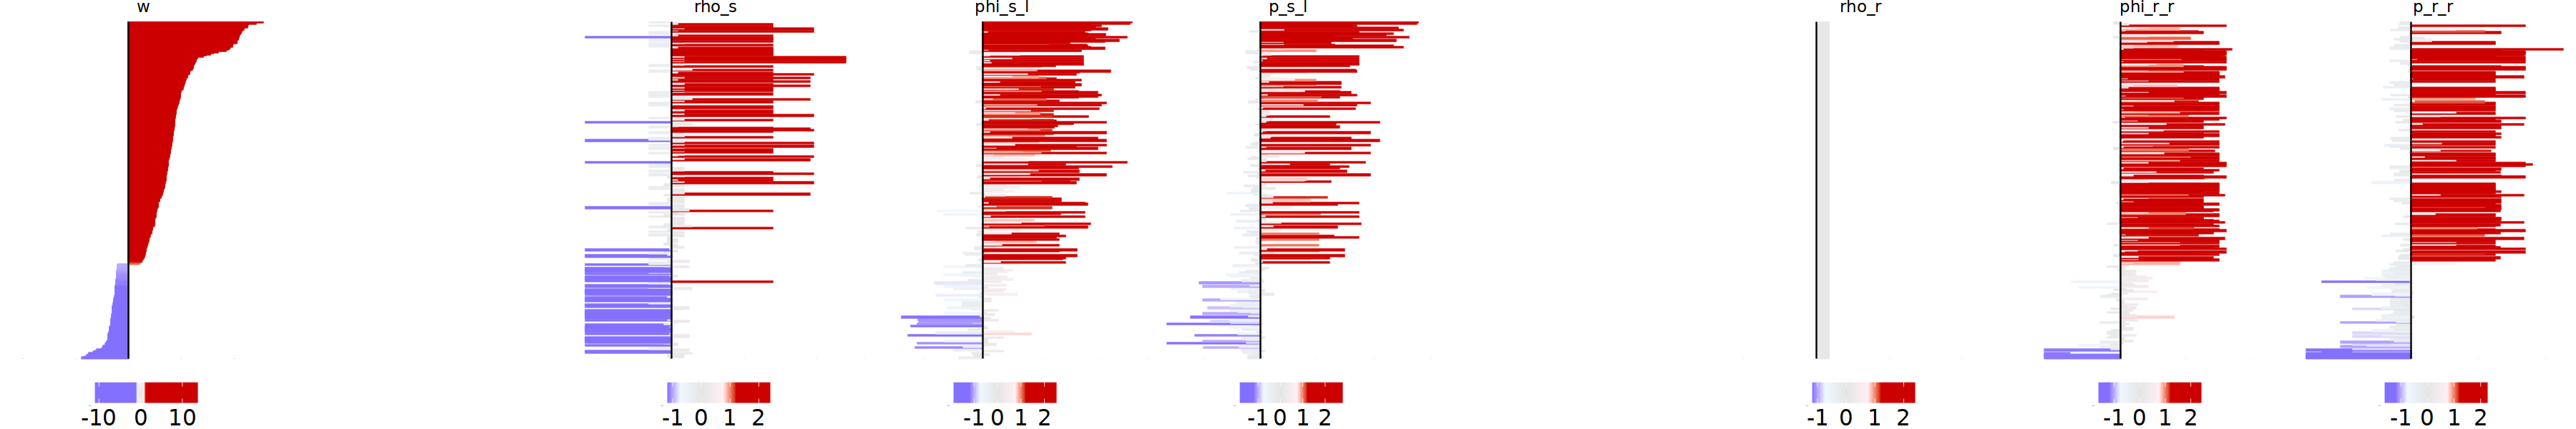

[1] "Cell Type: Macrophages - Number of interactions: 149"


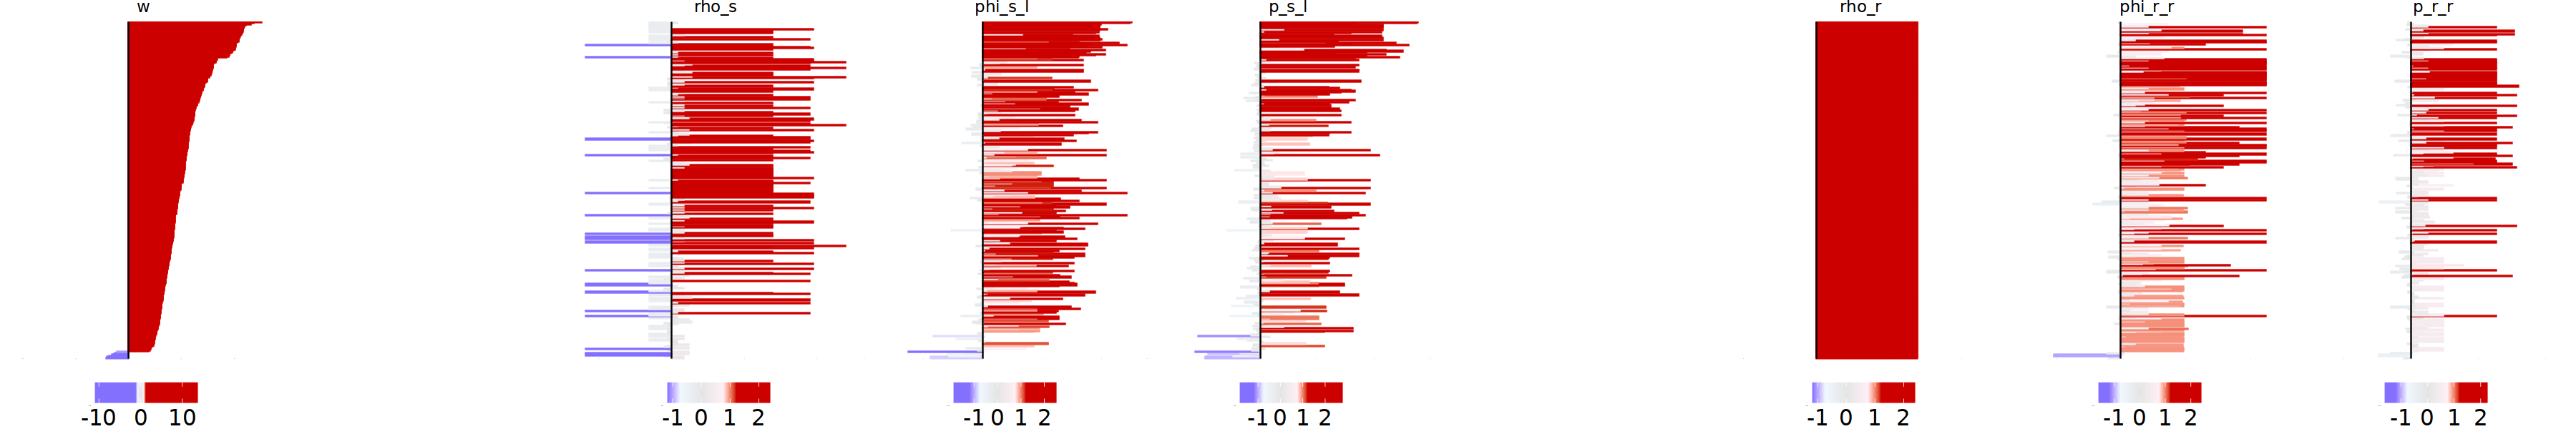

[1] "Cell Type: Myeloid - Number of interactions: 69"


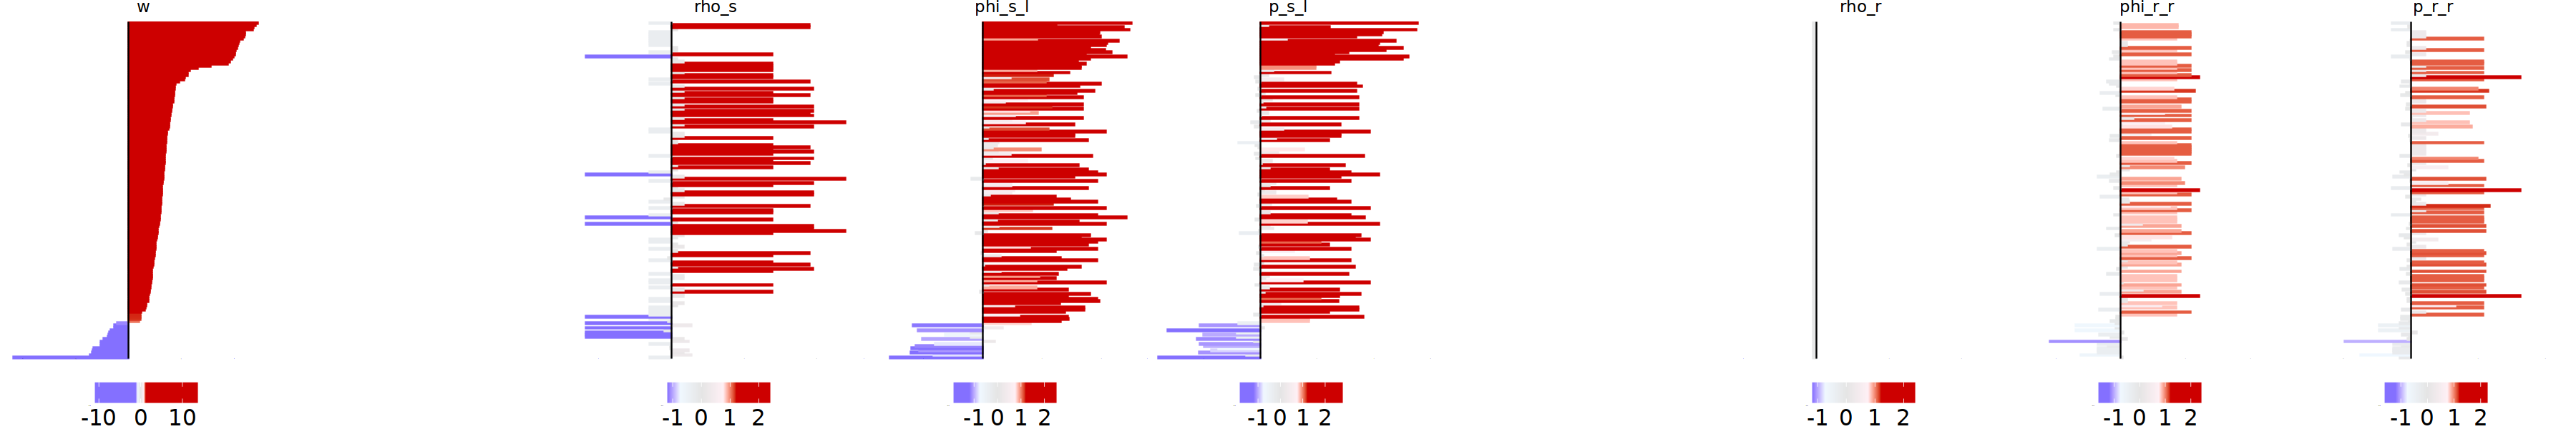

[1] "Cell Type: Mast - Number of interactions: 186"


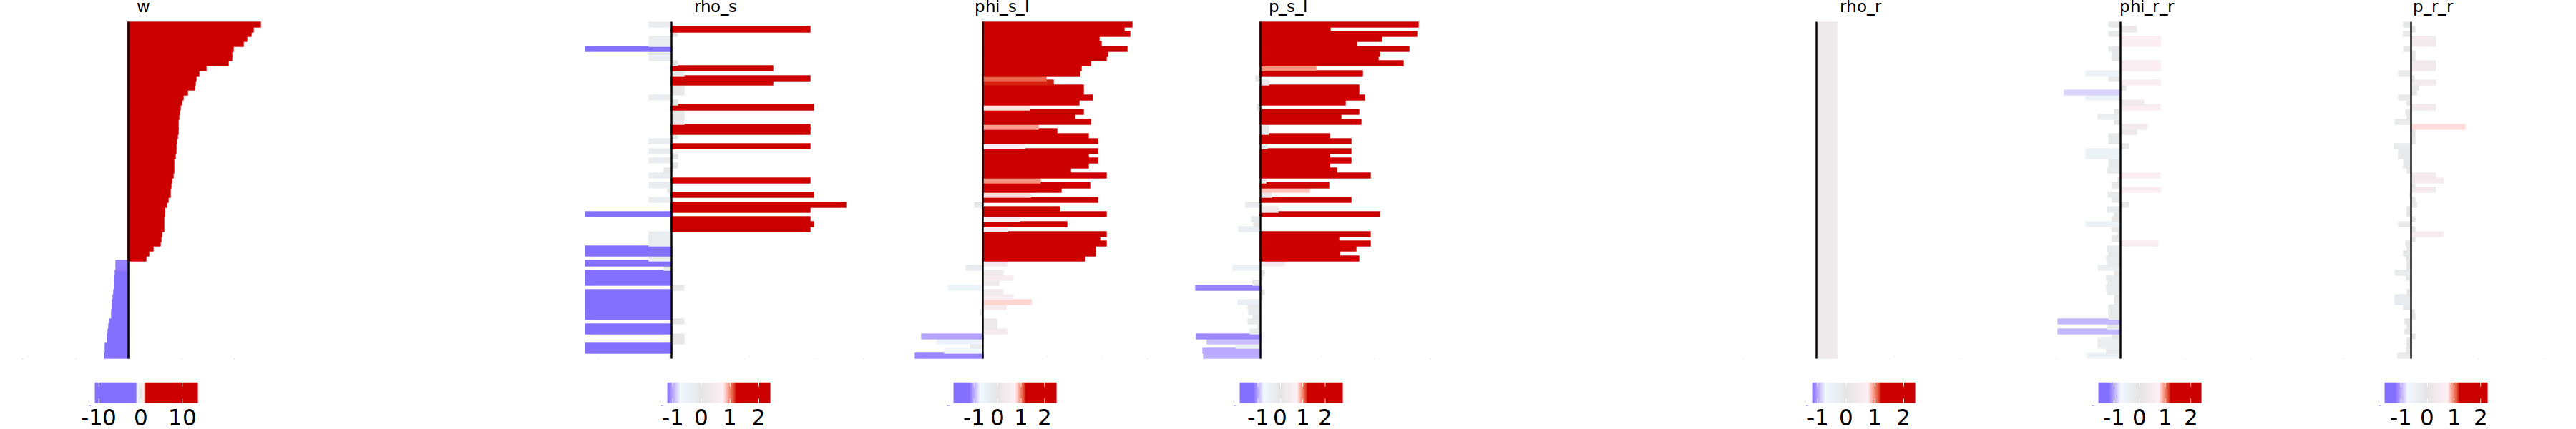

[1] "Cell Type: CD4 - Number of interactions: 123"


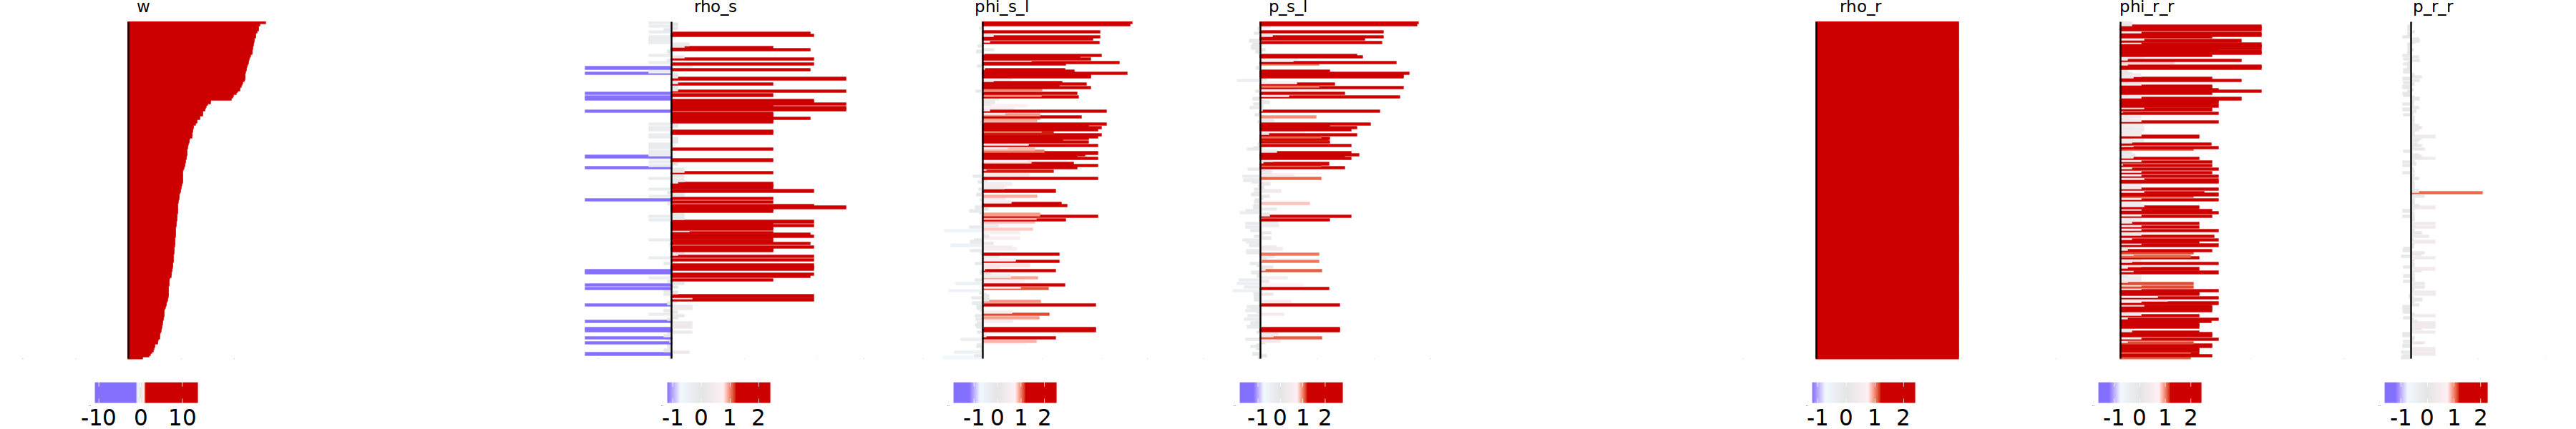

[1] "Cell Type: Tregs - Number of interactions: 209"


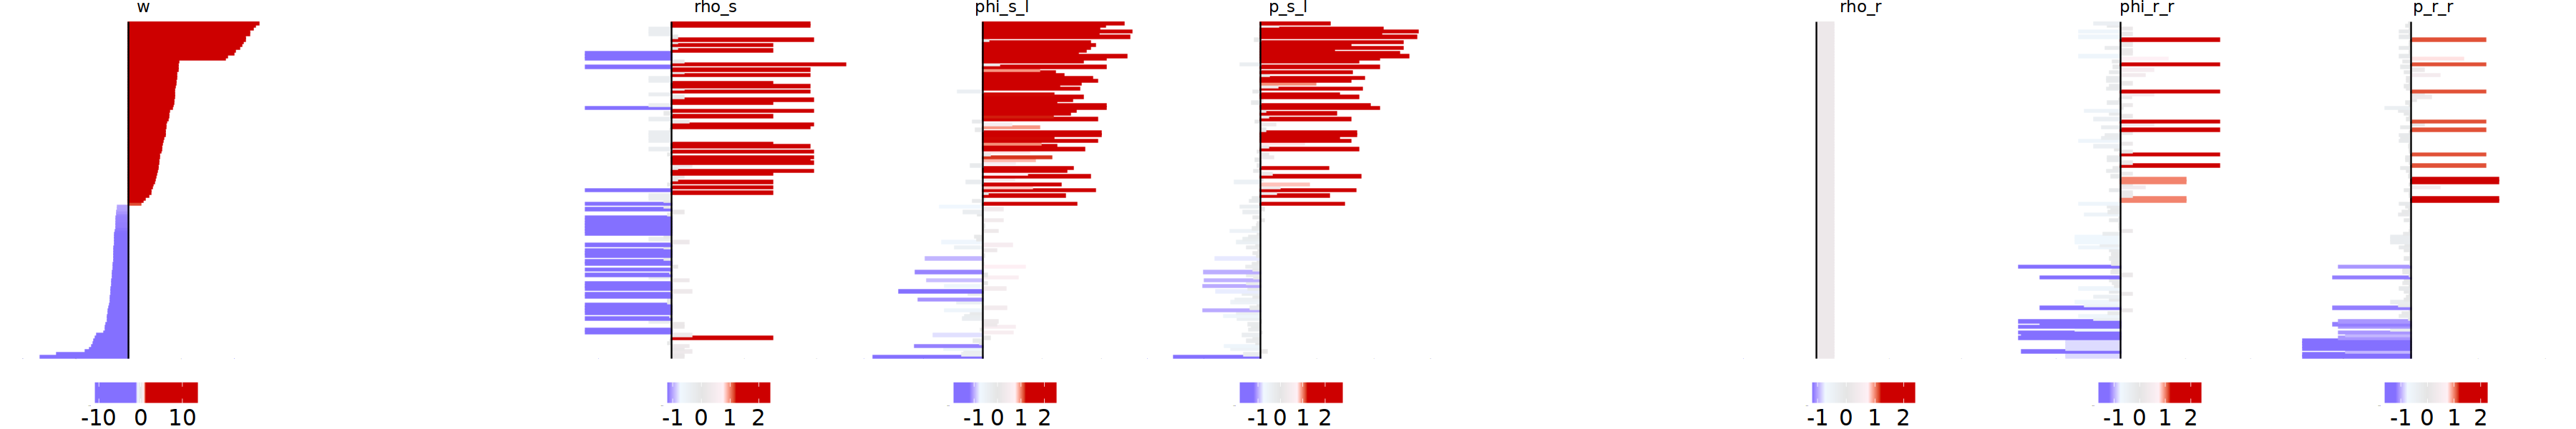

[1] "Cell Type: CD8 - Number of interactions: 104"


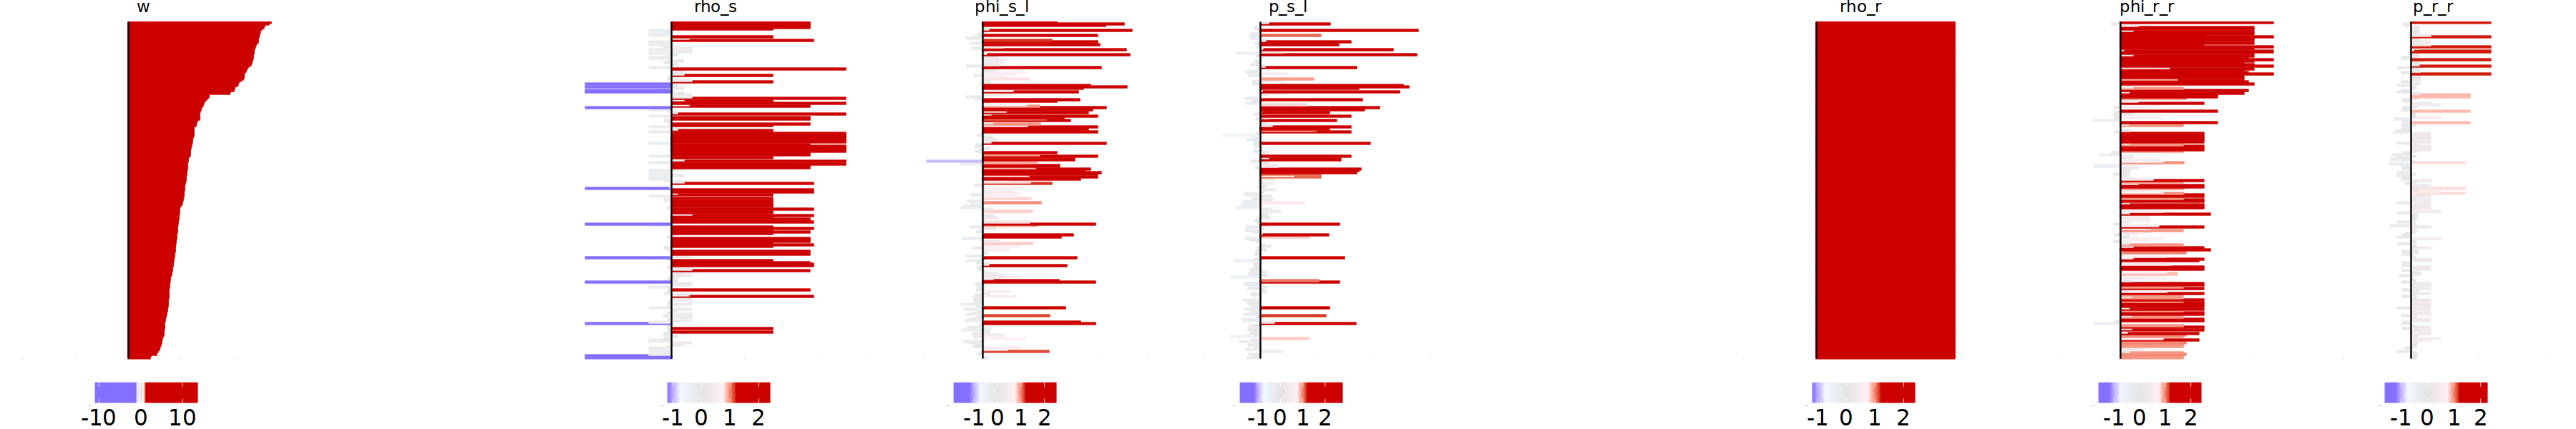

[1] "Cell Type: Plasma - Number of interactions: 146"


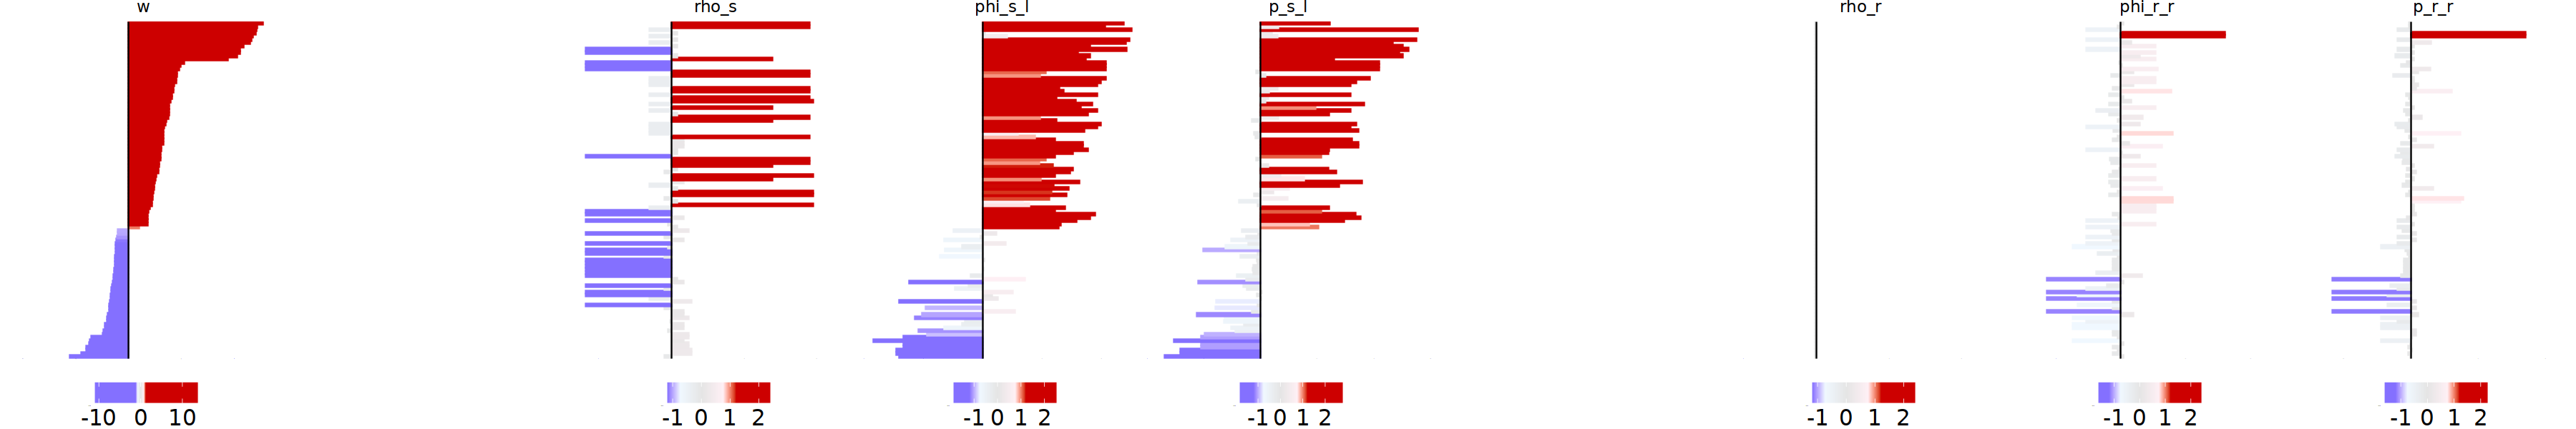

[1] "Cell Type: B-cells - Number of interactions: 44"


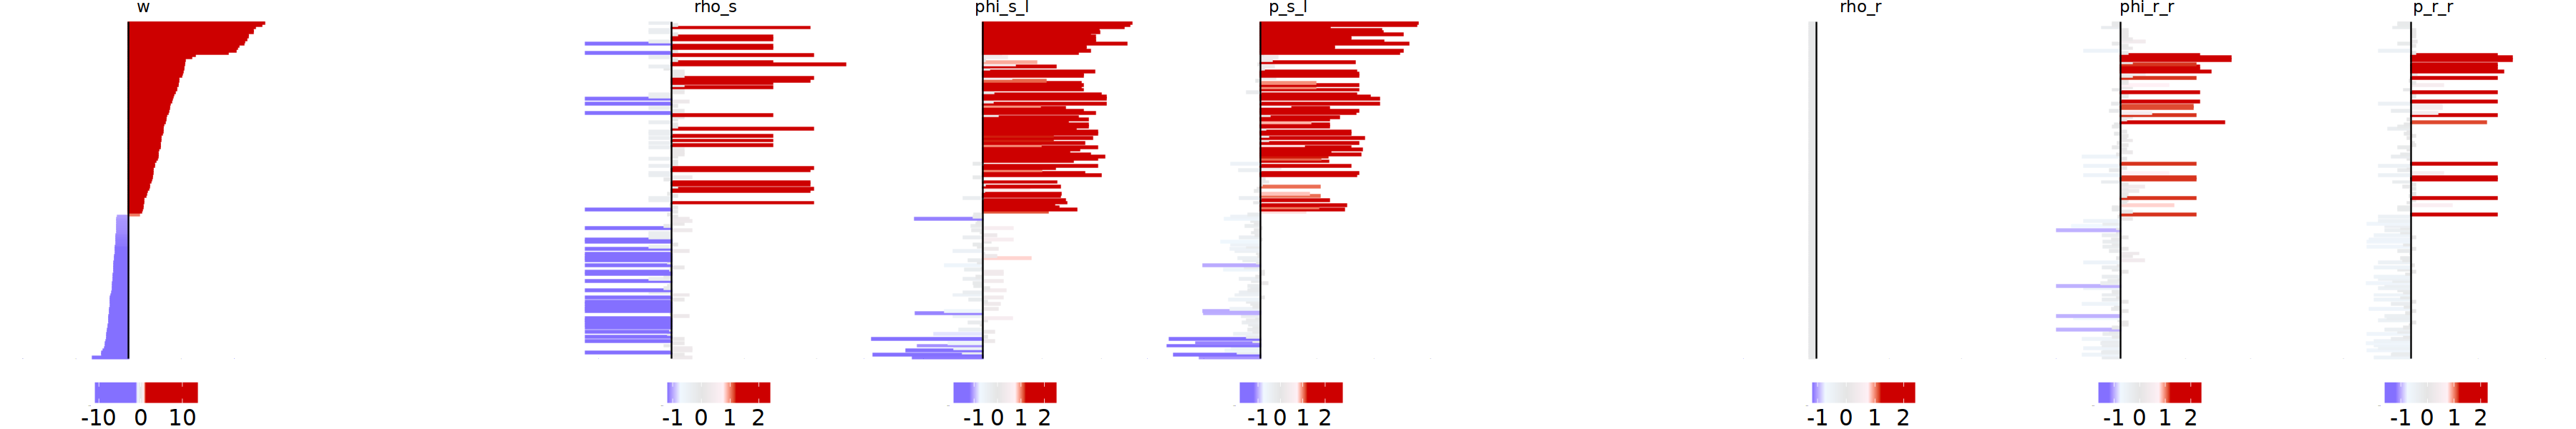

[1] "Total number of interactions across all receiving cell types: 3370"


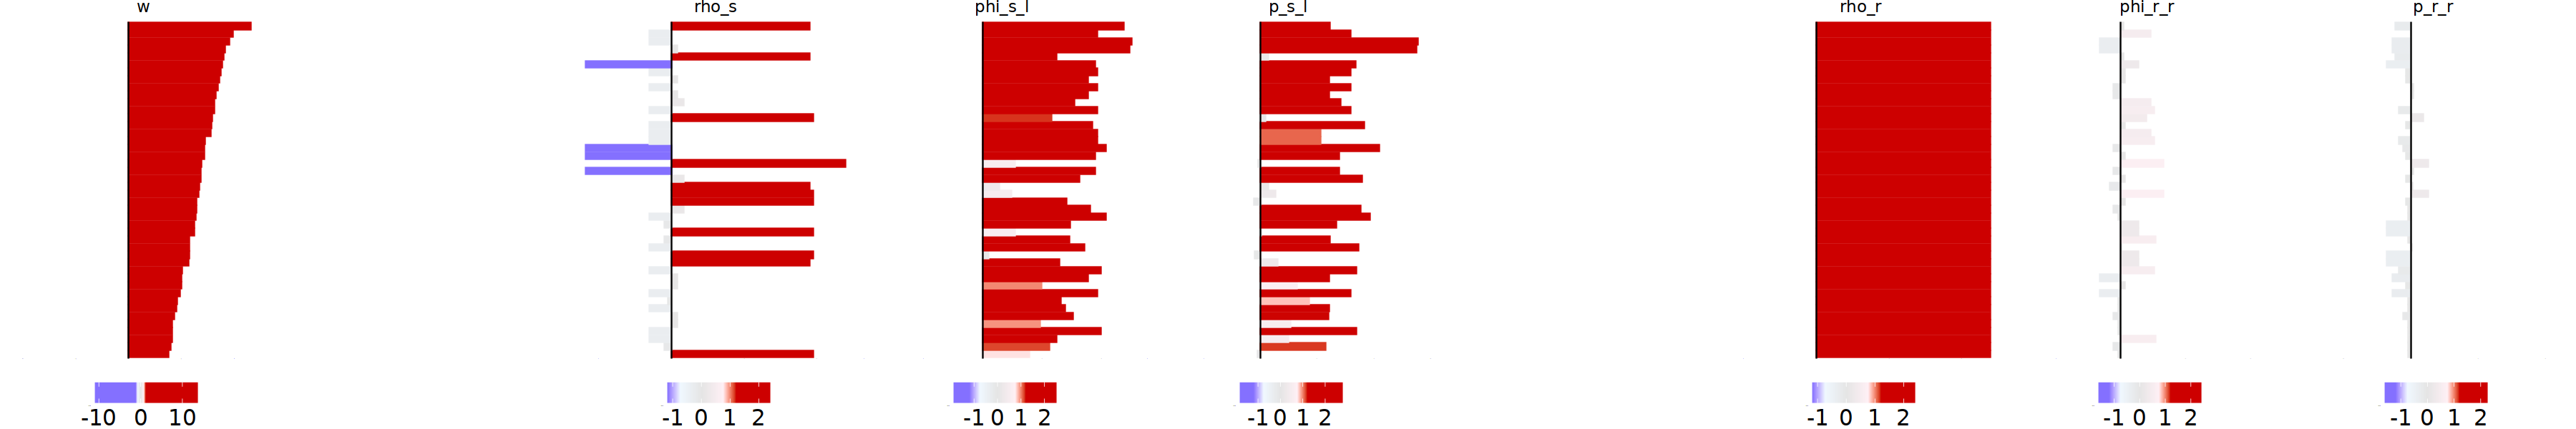

In [22]:
options(repr.plot.width = 30, repr.plot.height = 5)
receiving_cell_types <- unique(interactions$anno_interactions$receiving_cell_type)

total_interaction_count_receiving <- 0

for(cell_type in receiving_cell_types) {
    my_anno_interactions <- interactions$anno_interactions[interactions$anno_interactions$receiving_cell_type == cell_type & interactions$anno_interactions$interaction_ID %in% IDs, ]

    interaction_count <- nrow(my_anno_interactions)

    if(interaction_count > 0) {
        my_anno_interactions <- my_anno_interactions[order(my_anno_interactions$log2FC_weights), ]

        total_interaction_count_receiving <- total_interaction_count_receiving + interaction_count

        print(paste("Cell Type:", cell_type, "- Number of interactions:", interaction_count))

        plot_all_forests(my_idx = rep(TRUE, interaction_count),
                         my_anno_interactions = my_anno_interactions,
                         keep_order = TRUE,
                         threshold = 1,
                         legend_title_size = 0,
                         legend_text_size = 18,
                         component_lim = component_lim
                        )
    }
}
print(paste("Total number of interactions across all receiving cell types:", total_interaction_count_receiving))

# Export

In [ ]:
output_dir <- "./pdata/"

In [ ]:
write.csv(interactions$f_s, file = paste0(output_dir, "interactions_f_s.csv"), row.names = TRUE)
write.csv(interactions$f_r, file = paste0(output_dir, "interactions_f_r.csv"), row.names = TRUE)
write.csv(interactions$a_s, file = paste0(output_dir, "interactions_a_s.csv"), row.names = TRUE)
write.csv(interactions$a_r, file = paste0(output_dir, "interactions_a_r.csv"), row.names = TRUE)
write.csv(interactions$e_s_l, file = paste0(output_dir, "interactions_e_s_l.csv"), row.names = TRUE)
write.csv(interactions$e_r_r, file = paste0(output_dir, "interactions_e_r_r.csv"), row.names = TRUE)
write.csv(interactions$rho_r, file = paste0(output_dir, "interactions_rho_r.csv"), row.names = TRUE)
write.csv(interactions$rho_s, file = paste0(output_dir, "interactions_rho_s.csv"), row.names = TRUE)